# 🎵 Latin Music Genre Classifier
## Multi-Model Comparison: LightGBM · XGBoost · Neural Network

This notebook trains and compares three machine learning models to classify Latin music genres
from audio feature embeddings. The pipeline includes (v3 — calibration-leak fixes):

1. **Data loading & cleaning** – remove corrupt fragments and BPM outliers
2. **Three-way split** – train / val / **cal** / test (cal is a dedicated held-out split
   used only for calibration, temperature scaling, ensemble weight tuning and final NN
   early stopping — keeping val purely for Optuna tuning)
3. **Cluster-proximity stratification** – silhouette zones computed on trainval only,
   test songs assigned by nearest centroid (no test-set peeking)
4. **Augmentation & scaling** – Gaussian noise + Mixup + StandardScaler
5. **Hyperparameter tuning** – Optuna (Bayesian optimisation) for every model
6. **Baseline classifier** — minimum performance floor
7. **Song-level evaluation** – aggregate fragment probabilities per song
8. **Error analysis** + fragment consistency
9. **CV variance estimation** — 5-fold stability check

> **Dataset:** [Latin Music Embeddings](https://www.kaggle.com/datasets/g5fighter/latin-music-embeddings)
> **Key idea:** each song is split into multiple ~30 s fragments. We train on fragments but evaluate
> at the **song level** by aggregating fragment probabilities (max-pooling).


## 1 · Install Dependencies

`umap-learn` is used for optional dimensionality-reduction visualisations.  
`optuna-integration[tfkeras]` lets Optuna prune slow Keras trials early.


In [1]:
# Run once per session. The -q flag suppresses verbose pip output.
!pip install -q umap-learn optuna-integration[tfkeras] optuna[storages]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.2/103.2 kB 4.0 MB/s eta 0:00:00


## 2 · Imports

A global random seed (`SEED = 7`) is set for NumPy, TensorFlow and Optuna to ensure
reproducible results across runs. Using a value other than 42 makes it clear that
the results do not depend on a specific lucky seed.


In [2]:
import os, random
import pandas as pd
import numpy as np
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)   # keep output tidy

import tensorflow as tf

# ── Global seed (≠ 42 so results are not seed-specific) ──────────────────────
SEED = 7
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
# ── Deterministic GPU ops (TF ≥ 2.9) — small speed cost, full reproducibility ──
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass  # silently skip if not supported (CPU kernels or TF < 2.9)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_sample_weight

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from tensorflow import keras
from tensorflow.keras import layers, optimizers

import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary that will hold every trained model – populated in later cells
trained_models = {}


2026-05-21 13:26:56.944717: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779370017.141730      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779370017.197794      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779370017.642426      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779370017.642469      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779370017.642472      22 computation_placer.cc:177] computation placer alr

## 3 · Data Loading & Cleaning

### Why do we clean?
The dataset contains audio fragments extracted automatically from songs. Two known issues:

| Problem | Fix |
|---------|-----|
| **Fragments starting ≥ 300 s** – these often correspond to fade-outs or silence | Drop the **entire song** if any fragment starts that late |
| **BPM octave errors** – `librosa` can estimate BPM at 2× or 0.5× the true value | Accept a fragment if its BPM is within ±8 % of the song median, or its double/half |

After cleaning, the three-way **train / val / test** split is constructed using a
**cluster-proximity stratified** strategy (see §3.1 below) instead of a plain random split.


In [3]:
# ── Load ─────────────────────────────────────────────────────────────────────
df = pd.read_csv(
    '/kaggle/input/datasets/g5fighter/latin-music-embeddings/latin_music_features_dataset.csv'
)

# ── Fix 1: drop songs that have any late-starting fragment (≥ 300 s) ─────────
invalid_songs = df[df['fragment_start_sec'] >= 300]['song_id'].unique()
df_clean      = df[~df['song_id'].isin(invalid_songs)].copy()

# ── Fix 2: filter BPM outliers caused by librosa octave errors ───────────────
df_clean['median_bpm'] = df_clean.groupby('song_id')['bpm'].transform('median')
tol       = 0.08
is_normal = (df_clean['bpm'] - df_clean['median_bpm']).abs() / df_clean['median_bpm'] <= tol
is_double = (df_clean['bpm'] - df_clean['median_bpm'] * 2).abs() / (df_clean['median_bpm'] * 2) <= tol
is_half   = (df_clean['bpm'] - df_clean['median_bpm'] / 2).abs() / (df_clean['median_bpm'] / 2) <= tol
df        = df_clean[is_normal | is_double | is_half].drop(columns=['median_bpm']).copy()

# ── Initial feature / target arrays (zone split happens in §3.1 cell below) ──
cols_to_drop = ['genre', 'song_id', 'fragment_index', 'fragment_start_sec', 'track']
X        = df.drop(columns=cols_to_drop, errors='ignore')
y_text   = df['genre']
groups   = df['song_id']

le = LabelEncoder()
y  = le.fit_transform(y_text)
num_classes = len(le.classes_)

print(f"Fragments after cleaning: {len(df):,} | Songs: {groups.nunique():,} | "
      f"Genres: {num_classes} → {list(le.classes_)}")


Fragments after cleaning: 6,716 | Songs: 2,457 | Genres: 4 → ['Bachata', 'Merengue', 'Reggaeton', 'Salsa']


### 3.1 · Cluster-Proximity Stratified Split (with held-out CAL split)

We split songs into **train / val / cal / test** (groups respected, zone-stratified):

| Split  | Used for                                                                 |
|--------|--------------------------------------------------------------------------|
| train  | Fitting model weights                                                    |
| val    | Optuna hyperparameter tuning + ambiguity threshold + NN Optuna stopping  |
| **cal**| **Isotonic calibration, NN temperature scaling, NN final early-stopping, weighted-voting weight optimisation** |
| test   | Final reporting only — never touched until §6                            |

A dedicated `cal` split eliminates the calibration-leakage that arises when the same
`val` set guides hyperparameter selection and then is reused for calibration / ensemble
weight tuning.

**Silhouette zones** are computed only on `trainval` songs (no test-set peeking).
Test songs are assigned a zone by nearest centroid in the standardised song-feature space.


In [4]:
from sklearn.metrics import silhouette_samples

# ── Step 0: song-level mean feature vector (avoids fragment-count bias) ───────
X_arr    = X.values
y_arr    = y
song_ids = groups.values

df_song = pd.DataFrame(X_arr)
df_song['song_id'] = song_ids
df_song['label']   = y_arr
song_mean   = df_song.groupby('song_id').mean()           # mean feature per song
song_labels = song_mean['label'].astype(int).values
song_feat   = song_mean.drop(columns=['label']).values

# Normalise before silhouette so no feature dominates the distance
from sklearn.preprocessing import StandardScaler as _SS
_song_scaler = _SS()
song_feat_sc = _song_scaler.fit_transform(song_feat)

# ── Step 1: first split songs into trainval/test BEFORE computing silhouette ──
# This prevents test-set leakage through the cluster assignment used for stratification.
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
all_song_ids = song_mean.index.values
# We need to split songs, stratified by genre. GroupShuffleSplit doesn't stratify,
# so we use StratifiedGroupKFold at the fragment level which respects song groups.
sgkf_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_frag_idx, test_frag_idx = next(sgkf_split.split(X, y, groups=groups))

trainval_song_ids = np.unique(groups.iloc[trainval_frag_idx].values)
test_song_ids     = np.unique(groups.iloc[test_frag_idx].values)
assert len(set(trainval_song_ids) & set(test_song_ids)) == 0, 'song leak between trainval/test'

# ── Step 2: silhouette on TRAINVAL songs only ─────────────────────────────────
trainval_mask  = song_mean.index.isin(trainval_song_ids)
sil_tv         = silhouette_samples(song_feat_sc[trainval_mask], song_labels[trainval_mask])
song_mean.loc[trainval_mask, 'silhouette'] = sil_tv

# ── Step 3: zone assignment for trainval songs ────────────────────────────────
CORE_THRESHOLD = 0.15
def assign_zone(s):
    if s >= CORE_THRESHOLD:  return 'core'
    if s >= 0:               return 'boundary'
    return 'outlier'

song_mean.loc[trainval_mask, 'zone'] = song_mean.loc[trainval_mask, 'silhouette'].apply(assign_zone)

# ── Step 4: assign test-song zones by nearest centroid (no peeking) ───────────
# Build a per-(label, zone) centroid from trainval songs and map each test song
# to the zone of the nearest centroid within its own true-label cluster.
tv_song_mean_sc = pd.DataFrame(
    song_feat_sc[trainval_mask],
    index=song_mean.index[trainval_mask],
)
tv_song_mean_sc['label'] = song_labels[trainval_mask]
tv_song_mean_sc['zone']  = song_mean.loc[trainval_mask, 'zone'].values

zone_centroids = (tv_song_mean_sc
                  .groupby(['label', 'zone'])
                  .mean()
                  .drop(columns=[c for c in tv_song_mean_sc.columns
                                 if c in ('label', 'zone')], errors='ignore'))
# zone_centroids index = MultiIndex(label, zone), columns = feature dims

test_idx_in_sm = song_mean.index.get_indexer(test_song_ids)
test_song_feat_sc = song_feat_sc[test_idx_in_sm]
test_song_labels  = song_labels[test_idx_in_sm]

assigned_zones = []
for feat_vec, lab in zip(test_song_feat_sc, test_song_labels):
    cands = zone_centroids.xs(lab, level='label', drop_level=False)
    dists = np.linalg.norm(cands.values - feat_vec, axis=1)
    assigned_zones.append(cands.index[dists.argmin()][1])
song_mean.loc[test_song_ids, 'zone'] = assigned_zones

zone_counts = song_mean.groupby(['label', 'zone']).size().unstack(fill_value=0)
zone_counts.index = le.inverse_transform(zone_counts.index.astype(int))
print("Songs per genre / zone (trainval silhouette + nearest-centroid for test):")
print(zone_counts.to_string())
print(f"\nTotal  core: {(song_mean['zone']=='core').sum()}  "
      f"boundary: {(song_mean['zone']=='boundary').sum()}  "
      f"outlier: {(song_mean['zone']=='outlier').sum()}")

# ── Step 5: propagate zone to fragments and build strat key ───────────────────
song_zone_map = song_mean['zone'].to_dict()
df['zone']    = df['song_id'].map(song_zone_map)
df['strat_key'] = df['genre'] + '__' + df['zone']

cols_to_drop = ['genre', 'song_id', 'fragment_index', 'fragment_start_sec',
                'track', 'zone', 'strat_key']
X      = df.drop(columns=cols_to_drop, errors='ignore')
y_text = df['genre']
groups = df['song_id']
strat  = df['strat_key']

le = LabelEncoder()
y  = le.fit_transform(y_text)
num_classes = len(le.classes_)

strat_le  = LabelEncoder()
strat_enc = strat_le.fit_transform(strat)

# Re-derive the already-decided trainval/test indices on the fresh X (same rows, same order)
X_trainval      = X.iloc[trainval_frag_idx]
y_trainval      = y[trainval_frag_idx]
strat_trainval  = strat_enc[trainval_frag_idx]
groups_trainval = groups.iloc[trainval_frag_idx]

X_test      = X.iloc[test_frag_idx].copy()
y_test      = y[test_frag_idx]
groups_test = groups.iloc[test_frag_idx]

# ── Step 6: split trainval → train / val / cal (groups-respecting) ────────────
# We need three internal splits. Strategy:
#   1) 5-fold StratifiedGroupKFold on trainval, take 1 fold as "val+cal" (≈20%)
#   2) Split that 20% in half by songs → val (10%) and cal (10%)
sgkf_inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, valcal_idx = next(sgkf_inner.split(X_trainval, strat_trainval, groups=groups_trainval))

X_train      = X_trainval.iloc[train_idx].copy()
y_train      = y_trainval[train_idx]
groups_train = groups_trainval.iloc[train_idx]

X_valcal      = X_trainval.iloc[valcal_idx]
y_valcal      = y_trainval[valcal_idx]
strat_valcal  = strat_trainval[valcal_idx]
groups_valcal = groups_trainval.iloc[valcal_idx]

# Split val+cal half-and-half by songs (≈10% each of total trainval)
sgkf_vc = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED + 11)
val_inner_idx, cal_inner_idx = next(sgkf_vc.split(X_valcal, strat_valcal, groups=groups_valcal))

X_val      = X_valcal.iloc[val_inner_idx].copy()
y_val      = y_valcal[val_inner_idx]
groups_val = groups_valcal.iloc[val_inner_idx]

X_cal      = X_valcal.iloc[cal_inner_idx].copy()
y_cal      = y_valcal[cal_inner_idx]
groups_cal = groups_valcal.iloc[cal_inner_idx]

# Sanity: no song appears in more than one split
_song_sets = {
    'train': set(groups_train.unique()),
    'val'  : set(groups_val.unique()),
    'cal'  : set(groups_cal.unique()),
    'test' : set(groups_test.unique()),
}
for a in _song_sets:
    for b in _song_sets:
        if a != b:
            assert not (_song_sets[a] & _song_sets[b]), f'song leak between {a} and {b}'

# ── Step 7: proximity weights for the training fragments only ────────────────
zone_train = df.iloc[trainval_frag_idx].iloc[train_idx]['zone'].values
ZONE_WEIGHT = {'core': 1.0, 'boundary': 2.0, 'outlier': 2.0}
proximity_weights = np.array([ZONE_WEIGHT[z] for z in zone_train])

print(f"\nFragments  | train: {len(X_train):,}  val: {len(X_val):,}  "
      f"cal: {len(X_cal):,}  test: {len(X_test):,}")
print(f"Songs      | train: {groups_train.nunique():,}  val: {groups_val.nunique():,}  "
      f"cal: {groups_cal.nunique():,}  test: {groups_test.nunique():,}")


Songs per genre / zone (trainval silhouette + nearest-centroid for test):
zone       boundary  core  outlier
Bachata         354   467       81
Merengue        310    23      140
Reggaeton       409    96      193
Salsa           179   143       62

Total  core: 729  boundary: 1252  outlier: 476

Fragments  | train: 4,295  val: 545  cal: 545  test: 1,331
Songs      | train: 1,573  val: 196  cal: 197  test: 491


### 3.2 · Baseline Classifier

A `DummyClassifier` with `strategy='stratified'` assigns labels proportionally to class frequency.  
This is the **minimum acceptable performance** — any real model must beat it comfortably.  
All downstream metrics should be read relative to these numbers.


In [5]:
# ── Stratified dummy baseline ─────────────────────────────────────────────
dummy = DummyClassifier(strategy='stratified', random_state=SEED)
dummy.fit(X_train, y_train)

# Evaluate at song level (same protocol as real models)
dummy_probs_frag = dummy.predict_proba(X_test)
prob_cols_dummy  = le.classes_.tolist()
df_dummy = pd.DataFrame(dummy_probs_frag, columns=prob_cols_dummy)
df_dummy['song_id'] = groups_test.values
df_dummy['y_true']  = y_test
song_dummy = df_dummy.groupby('song_id')[prob_cols_dummy].mean()
song_dummy_y = df_dummy.groupby('song_id')['y_true'].first().astype(int)
y_dummy_pred = song_dummy.values.argmax(axis=1)

baseline_acc = accuracy_score(song_dummy_y, y_dummy_pred)
baseline_f1  = f1_score(song_dummy_y, y_dummy_pred, average='macro')
print(f"Baseline (stratified dummy) — Song-level Accuracy: {baseline_acc:.4f}  |  F1-Macro: {baseline_f1:.4f}")
print("Any model must exceed these numbers to be considered useful.")


Baseline (stratified dummy) — Song-level Accuracy: 0.2892  |  F1-Macro: 0.2202
Any model must exceed these numbers to be considered useful.


## 4 · Data Augmentation & Feature Scaling

### Gaussian noise augmentation
We double the training set by adding small Gaussian noise (σ = 0.02) to every feature.  
This acts as a regulariser and makes the models more robust to natural variation in audio features.

> ⚠️ Augmentation is applied **only to the training set**. Validation and test sets are left untouched.

**`groups_train_aug`** is also duplicated so it stays aligned with the augmented feature matrix
— this is required for any downstream cross-validation step that uses group information.

### StandardScaler
Centers each feature to zero mean and scales to unit variance.  
Fit on training data only → transform train, val, and test.  
This is critical for the Neural Network and also helps gradient-boosting models converge faster.


In [6]:
def add_gaussian_noise(data: np.ndarray, noise_level: float = 0.01,
                       rng: np.random.Generator = None) -> np.ndarray:
    """Return a copy of `data` with independent Gaussian noise added."""
    if rng is None:
        rng = np.random.default_rng(SEED)
    noise = rng.normal(0, noise_level, data.shape)
    return data + noise


def mixup_augment(X: np.ndarray, y: np.ndarray, weights: np.ndarray,
                  alpha: float = 0.2, n_samples: int = None,
                  rng: np.random.Generator = None) -> tuple:
    """Mixup augmentation: interpolate pairs of samples and blend their labels.

    Returns (X_mix, y_mix, w_mix, idx_a). We also return idx_a so the caller can
    assign the synthetic samples a group id (we choose the dominant parent's
    group, matching the same rule we use for the hard label).
    """
    if rng is None:
        rng = np.random.default_rng(SEED)
    n = len(X)
    if n_samples is None:
        n_samples = n
    lam = rng.beta(alpha, alpha, size=n_samples)
    idx_a = rng.integers(0, n, size=n_samples)
    idx_b = rng.integers(0, n, size=n_samples)
    X_mix = lam[:, None] * X[idx_a] + (1 - lam[:, None]) * X[idx_b]
    # Hard labels: pick the dominant class by lambda
    dominant_idx = np.where(lam >= 0.5, idx_a, idx_b)
    y_mix = y[dominant_idx]
    # Weights: blend the proximity weights of the two parents
    w_mix = lam * weights[idx_a] + (1 - lam) * weights[idx_b]
    return X_mix, y_mix, w_mix, dominant_idx


# Fit scaler on ORIGINAL X_train only, THEN augment in scaled space
scaler          = StandardScaler()
X_train_orig_sc = scaler.fit_transform(X_train)
X_val_scaled    = scaler.transform(X_val)
X_cal_scaled    = scaler.transform(X_cal)
X_test_scaled   = scaler.transform(X_test)

# ── Augmentation 1: Gaussian noise (doubles the training set) ────────────────
_rng = np.random.default_rng(SEED)
X_train_noise = add_gaussian_noise(X_train_orig_sc, noise_level=0.02, rng=_rng)

# ── Augmentation 2: Mixup (adds N more interpolated samples) ────────────────
# alpha=0.2 → Beta(0.2,0.2) is U-shaped: most λ near 0 or 1, gentle interpolation
N_MIXUP = len(X_train_orig_sc) // 2   # add 50% extra samples via mixup
X_mix, y_mix, w_mix, dominant_idx = mixup_augment(
    X_train_orig_sc, y_train, proximity_weights,
    alpha=0.2, n_samples=N_MIXUP, rng=_rng,
)

# ── Stack: original + gaussian + mixup ───────────────────────────────────────
X_train_scaled  = np.vstack([X_train_orig_sc, X_train_noise, X_mix])
y_train_aug     = np.concatenate([y_train, y_train, y_mix])
# Mixup samples inherit the song_id of their dominant parent (matches the y_mix rule)
mixup_groups = groups_train.values[dominant_idx]
groups_train_aug = pd.concat([
    groups_train, groups_train, pd.Series(mixup_groups)
]).reset_index(drop=True)
proximity_weights_aug = np.concatenate([proximity_weights, proximity_weights, w_mix])

# Keep a reference to the original-only scaled array for stacking OOF later
X_train_orig_scaled = X_train_orig_sc

print(f"Training set after augmentation: {X_train_scaled.shape[0]:,} fragments")
print(f"  Original         : {len(X_train_orig_sc):,}")
print(f"  + Gaussian noise : {len(X_train_noise):,}")
print(f"  + Mixup          : {N_MIXUP:,}")
print(f"Scaler fitted on {X_train_orig_sc.shape[0]:,} original fragments (no duplicates)")


Training set after augmentation: 10,737 fragments
  Original         : 4,295
  + Gaussian noise : 4,295
  + Mixup          : 2,147
Scaler fitted on 4,295 original fragments (no duplicates)


## 5 · Hyperparameter Tuning with Optuna

[Optuna](https://optuna.org/) performs **Bayesian optimisation** (TPE sampler by default).  
Each *trial* trains a model with a candidate set of hyperparameters and returns the
**macro F1-score** on the **validation set** (`X_val_scaled`) as the objective to maximise.

> ⚠️ The **test set is never seen during tuning**. It is used only in §6 for the final evaluation.

| Model | Trials | Search space highlights |
|-------|--------|------------------------|
| LightGBM | 15 | `n_estimators`, `learning_rate`, `num_leaves` |
| XGBoost  | 15 | `n_estimators`, `learning_rate`, `max_depth`, `subsample` |
| Neural Net | 10 | layer sizes, dropout rates, learning rate |

> **GPU acceleration** is enabled for LightGBM (`device='gpu'`) and XGBoost
> (`tree_method='hist'`, `device='cuda'`).  
> If you run on a CPU-only kernel, change those settings to `device='cpu'` / remove `device='cuda'`.


### 5.1 · LightGBM

In [7]:
def objective_lgb(trial):
    params = {
        'n_estimators' : trial.suggest_int  ('n_estimators',  50, 400),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'num_leaves'   : trial.suggest_int  ('num_leaves',    20,  150),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample'    : trial.suggest_float('subsample',     0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha'    : trial.suggest_float('reg_alpha',     1e-8, 10.0, log=True),
        'reg_lambda'   : trial.suggest_float('reg_lambda',    1e-8, 10.0, log=True),
        'random_state' : SEED,
        'verbose'      : -1,
        'device'       : 'gpu',   # change to 'cpu' if no GPU is available
    }
    # FIX: combine class-balance × proximity weights explicitly (same recipe as XGB).
    # Previously class_weight='balanced' was applied ALONG with proximity weights,
    # which effectively double-weighted minority-class boundary fragments.
    cls_w     = compute_sample_weight('balanced', y_train_aug)
    sample_w  = cls_w * proximity_weights_aug
    model = LGBMClassifier(**params)
    model.fit(X_train_scaled, y_train_aug, sample_weight=sample_w)
    preds = model.predict(X_val_scaled)
    return f1_score(y_val, preds, average='macro')

storage_lgb = optuna.storages.RDBStorage('sqlite:////kaggle/working/optuna_lgb.db')
study_lgb = optuna.create_study(
    direction='maximize', study_name='LightGBM',
    storage=storage_lgb, load_if_exists=True,
)
study_lgb.optimize(objective_lgb, n_trials=20)

print(f"Best LightGBM F1  : {study_lgb.best_value:.4f}")
print(f"Best LightGBM params: {study_lgb.best_params}")

# Retrain with best params on full augmented training set
best_lgb = LGBMClassifier(
    **study_lgb.best_params,
    random_state=SEED, verbose=-1, device='gpu',
)
cls_w_full    = compute_sample_weight('balanced', y_train_aug)
sample_w_full = cls_w_full * proximity_weights_aug
best_lgb.fit(X_train_scaled, y_train_aug, sample_weight=sample_w_full)

# FIX: calibrate on the dedicated CAL split (never used for tuning).
best_lgb_cal = CalibratedClassifierCV(best_lgb, method='isotonic', cv='prefit')
best_lgb_cal.fit(X_cal_scaled, y_cal)

trained_models['LightGBM'] = best_lgb_cal
print(f"LGBM calibrated on {len(X_cal_scaled)} held-out CAL fragments.")


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature 

Best LightGBM F1  : 0.9322
Best LightGBM params: {'n_estimators': 95, 'learning_rate': 0.09927976548702112, 'num_leaves': 76, 'min_child_samples': 56, 'subsample': 0.9986949208445459, 'colsample_bytree': 0.9808365306202121, 'reg_alpha': 8.458376223117945, 'reg_lambda': 0.01569944493429779}
LGBM calibrated on 545 held-out CAL fragments.


/usr/local/lib/python3.12/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### 5.2 · XGBoost

In [8]:
def objective_xgb(trial):
    params = {
        'n_estimators'     : trial.suggest_int  ('n_estimators',      50, 400),
        'learning_rate'    : trial.suggest_float('learning_rate',     1e-3, 0.1, log=True),
        'max_depth'        : trial.suggest_int  ('max_depth',          3,  12),
        'subsample'        : trial.suggest_float('subsample',         0.6, 1.0),
        'colsample_bytree' : trial.suggest_float('colsample_bytree',  0.5, 1.0),
        'min_child_weight' : trial.suggest_int  ('min_child_weight',   1,  10),
        'gamma'            : trial.suggest_float('gamma',             0.0,  5.0),
        'reg_alpha'        : trial.suggest_float('reg_alpha',         1e-8, 10.0, log=True),
        'reg_lambda'       : trial.suggest_float('reg_lambda',        1e-8, 10.0, log=True),
        'objective'        : 'multi:softprob',
        'num_class'        : num_classes,
        'random_state'     : SEED,
        'tree_method'      : 'hist',
        'device'           : 'cuda',  # change to 'cpu' if no GPU is available
    }
    cls_w     = compute_sample_weight('balanced', y_train_aug)
    sample_w  = cls_w * proximity_weights_aug
    model = XGBClassifier(**params)
    model.fit(X_train_scaled, y_train_aug, sample_weight=sample_w)
    preds = model.predict(X_val_scaled)
    return f1_score(y_val, preds, average='macro')

storage_xgb = optuna.storages.RDBStorage('sqlite:////kaggle/working/optuna_xgb.db')
study_xgb = optuna.create_study(
    direction='maximize', study_name='XGBoost',
    storage=storage_xgb, load_if_exists=True,
)
study_xgb.optimize(objective_xgb, n_trials=20)

print(f"Best XGBoost F1  : {study_xgb.best_value:.4f}")
print(f"Best XGBoost params: {study_xgb.best_params}")

cls_w_full     = compute_sample_weight('balanced', y_train_aug)
sample_w_full  = cls_w_full * proximity_weights_aug
best_xgb = XGBClassifier(
    **study_xgb.best_params,
    objective='multi:softprob', num_class=num_classes, random_state=SEED,
    tree_method='hist', device='cuda',
)
best_xgb.fit(X_train_scaled, y_train_aug, sample_weight=sample_w_full)

# FIX: calibrate on the dedicated CAL split (independent of val).
best_xgb_cal = CalibratedClassifierCV(best_xgb, method='isotonic', cv='prefit')
best_xgb_cal.fit(X_cal_scaled, y_cal)

trained_models['XGBoost'] = best_xgb_cal
print(f"XGB calibrated on {len(X_cal_scaled)} held-out CAL fragments.")


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [13:41:55] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Best XGBoost F1  : 0.9271
Best XGBoost params: {'n_estimators': 343, 'learning_rate': 0.07331165426796432, 'max_depth': 5, 'subsample': 0.8054821181643843, 'colsample_bytree': 0.5180604286789481, 'min_child_weight': 3, 'gamma': 3.0986155889491735, 'reg_alpha': 1.3634657853273465e-08, 'reg_lambda': 6.000665135751995e-08}
XGB calibrated on 545 held-out CAL fragments.


/usr/local/lib/python3.12/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


### 5.3 · Neural Network

Architecture: two fully-connected layers with **BatchNormalization** and **Dropout** for regularisation.  
The final layer uses **softmax** to output a probability distribution over genres.

The TensorFlow global seed (`SEED = 7`) was set in §2, so training is reproducible.  
Optuna evaluates each trial on `X_val_scaled` (not the test set).


In [9]:
def build_nn(trial, input_dim, num_classes):
    """Build a variable-depth MLP from trial hyperparameters."""
    n_layers    = trial.suggest_int  ('n_layers',  1, 4)
    activation  = trial.suggest_categorical('activation', ['relu', 'gelu', 'elu'])
    lr          = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    l2_reg      = trial.suggest_float('l2_reg', 1e-6, 1e-2, log=True)

    model = keras.Sequential()
    model.add(layers.InputLayer(shape=(input_dim,)))
    for k in range(n_layers):
        units = trial.suggest_int(f'units_{k}', 64, 512, step=64)
        drop  = trial.suggest_float(f'drop_{k}', 0.1, 0.5)
        model.add(layers.Dense(units, activation=activation,
                               kernel_regularizer=keras.regularizers.l2(l2_reg)))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(drop))
    model.add(layers.Dense(num_classes, activation='softmax'))
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


def objective_nn(trial):
    tf.random.set_seed(SEED)
    model = build_nn(trial, X_train_scaled.shape[1], num_classes)

    class_sw = compute_sample_weight('balanced', y_train_aug)
    sw = class_sw * proximity_weights_aug

    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )
    pruning_cb = optuna.integration.TFKerasPruningCallback(trial, 'val_loss')
    model.fit(X_train_scaled, y_train_aug,
              sample_weight=sw,
              epochs=30, batch_size=64, verbose=0,
              validation_data=(X_val_scaled, y_val),
              callbacks=[early_stop, pruning_cb])
    preds = model.predict(X_val_scaled, verbose=0).argmax(axis=1)
    return f1_score(y_val, preds, average='macro')


storage_nn = optuna.storages.RDBStorage('sqlite:////kaggle/working/optuna_nn.db')
pruner_nn  = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)
study_nn = optuna.create_study(
    direction='maximize', study_name='Neural Network',
    storage=storage_nn, load_if_exists=True,
    pruner=pruner_nn,
)
study_nn.optimize(objective_nn, n_trials=30)

print(f"Best NN F1  : {study_nn.best_value:.4f}")
print(f"Best NN params: {study_nn.best_params}")
n_pruned = len([t for t in study_nn.trials if t.state == optuna.trial.TrialState.PRUNED])
print(f"Trials pruned early: {n_pruned} / {len(study_nn.trials)}")

# ── Final retrain. We use CAL for early stopping (val already shaped the
# architecture choice) so the early-stopping epoch isn't itself overfit to val. ──
tf.random.set_seed(SEED)
best_nn = build_nn(study_nn.best_trial, X_train_scaled.shape[1], num_classes)
class_sw_full = compute_sample_weight('balanced', y_train_aug)
sw_full = class_sw_full * proximity_weights_aug
early_stop_final = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=0
)
plateau_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=0
)
# Use CAL for early-stopping monitoring; we'll do temperature scaling on a
# fresh sub-split of CAL afterwards so calibration data is still held out
# from the early-stopping signal.
X_es, X_temp, y_es, y_temp = tts(
    X_cal_scaled, y_cal, test_size=0.5, random_state=SEED + 3, stratify=y_cal
)

best_nn.fit(X_train_scaled, y_train_aug,
            sample_weight=sw_full,
            epochs=100, batch_size=64, verbose=0,
            validation_data=(X_es, y_es),
            callbacks=[early_stop_final, plateau_lr])

# ── Temperature Scaling calibration for the NN ────────────────────────────────
# Fit T on X_temp (the half of CAL NOT used for early stopping) → no leakage.
from scipy.optimize import minimize_scalar

# Warm-up call so Keras registers the inbound node
_dummy = tf.constant(X_temp[:1], dtype=tf.float32)
_ = best_nn(_dummy, training=False)

# Build a logit extractor: clone the last Dense layer with linear activation
penultimate_output = best_nn.layers[-2].output
last_layer = best_nn.layers[-1]
linear_layer = keras.layers.Dense(last_layer.units, activation=None)
logits = linear_layer(penultimate_output)
_logit_model = keras.Model(inputs=best_nn.inputs, outputs=logits)
linear_layer.set_weights(last_layer.get_weights())

_logits_cal = _logit_model.predict(X_temp, verbose=0).astype(np.float64)

def _nll(T):
    """Negative log-likelihood of calibration labels under temperature T."""
    scaled = _logits_cal / T
    shifted = scaled - scaled.max(1, keepdims=True)
    log_softmax = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
    return -log_softmax[np.arange(len(y_temp)), y_temp].mean()

result_T = minimize_scalar(_nll, bounds=(0.1, 10.0), method='bounded')
TEMPERATURE = result_T.x
print(f"\nTemperature scaling T = {TEMPERATURE:.4f}  (T>1 = overconfident, T<1 = underconfident)")
print(f"Fitted on {len(X_temp)} CAL fragments (held out from early-stopping signal).")

class TemperatureScaledNN:
    """Wrapper: divides logits by T before softmax → calibrated probs."""
    def __init__(self, keras_model, logit_model, T):
        self.keras_model = keras_model
        self.logit_model = logit_model
        self.T = T

    def predict(self, X, verbose=0):
        logits = self.logit_model.predict(X, verbose=verbose).astype(np.float64)
        scaled = logits / self.T
        exp_s  = np.exp(scaled - scaled.max(1, keepdims=True))
        return exp_s / exp_s.sum(1, keepdims=True)

best_nn_cal = TemperatureScaledNN(best_nn, _logit_model, TEMPERATURE)
trained_models['NeuralNetwork'] = best_nn_cal
print("NeuralNetwork stored with temperature calibration.")


I0000 00:00:1779371159.684182      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13733 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779371159.689749      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
2026-05-21 13:46:01.246506: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be 

Best NN F1  : 0.9186
Best NN params: {'n_layers': 4, 'activation': 'relu', 'lr': 0.00016414365900359952, 'l2_reg': 3.552577177566652e-06, 'units_0': 448, 'drop_0': 0.4948486727514766, 'units_1': 256, 'drop_1': 0.26087559657522974, 'units_2': 64, 'drop_2': 0.4277430170237627, 'units_3': 320, 'drop_3': 0.3505456982648826}
Trials pruned early: 21 / 30


2026-05-21 13:54:34.406622: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}
2026-05-21 13:55:01.228155: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),


Temperature scaling T = 1.3094  (T>1 = overconfident, T<1 = underconfident)
Fitted on 273 CAL fragments (held out from early-stopping signal).
NeuralNetwork stored with temperature calibration.


## 6 · Song-Level Evaluation

### Why evaluate at song level?
Each song contributes **multiple fragments** to the test set.  
A fragment-level metric would overcount songs with many fragments and undercount short ones.  
We compare two aggregation strategies:

| Strategy | Logic | When it shines |
|----------|--------|---------------|
| **Max-pooling** | Take the highest predicted probability per genre across all fragments | One very confident fragment is enough |
| **Mean-pooling** | Average predicted probabilities across fragments | All fragments vote equally; more robust to outliers |


In [10]:
results = []

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=500, ci=0.95, seed=SEED):
    """Return (lower, upper) bootstrap percentile CI for metric_fn."""
    rng = np.random.default_rng(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    lo = np.percentile(scores, (1 - ci) / 2 * 100)
    hi = np.percentile(scores, (1 + ci) / 2 * 100)
    return lo, hi


def aggregate_and_score(name, model, pooling='max'):
    """Aggregate fragment probabilities at song level and return accuracy + F1 + 95% CI."""
    if name == 'NeuralNetwork':
        probs = model.predict(X_test_scaled, verbose=0)
    else:
        probs = model.predict_proba(X_test_scaled)

    prob_cols = le.classes_.tolist()
    df_preds = pd.DataFrame(probs, columns=prob_cols)
    df_preds['song_id'] = groups_test.values
    df_preds['y_true']  = y_test

    if pooling == 'max':
        song_probs = df_preds.groupby('song_id')[prob_cols].max()
    else:
        song_probs = df_preds.groupby('song_id')[prob_cols].mean()
    song_ytrue = df_preds.groupby('song_id')['y_true'].first()
    song_preds = song_probs.copy()
    song_preds['y_true'] = song_ytrue

    y_song_true     = song_preds['y_true'].astype(int).values
    y_song_pred_idx = song_preds[prob_cols].values.argmax(axis=1)

    acc = accuracy_score(y_song_true, y_song_pred_idx)
    f1  = f1_score(y_song_true, y_song_pred_idx, average='macro')

    acc_ci = bootstrap_ci(y_song_true, y_song_pred_idx, accuracy_score)
    f1_ci  = bootstrap_ci(y_song_true, y_song_pred_idx,
                          lambda yt, yp: f1_score(yt, yp, average='macro'))
    return acc, f1, acc_ci, f1_ci


for name, model in trained_models.items():
    for pooling in ('max', 'mean'):
        acc, f1, acc_ci, f1_ci = aggregate_and_score(name, model, pooling)
        results.append({
            'Model'        : name,
            'Pooling'      : pooling,
            'Accuracy'     : round(acc, 4),
            'Acc 95% CI'   : f'[{acc_ci[0]:.3f}, {acc_ci[1]:.3f}]',
            'F1-Macro'     : round(f1, 4),
            'F1 95% CI'    : f'[{f1_ci[0]:.3f}, {f1_ci[1]:.3f}]',
        })

df_results = (pd.DataFrame(results)
                   .sort_values('F1-Macro', ascending=False)
                   .reset_index(drop=True))
display(df_results)

# Best BASE-model pooling (Stacking/WeightedVoting added later)
best_row     = df_results.iloc[0]
BEST_POOLING = best_row['Pooling']
print(f"\n✅ Best configuration: {best_row['Model']} with {BEST_POOLING}-pooling "
      f"(F1={best_row['F1-Macro']:.4f}, 95% CI={best_row['F1 95% CI']})")


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
2026-05-21 13:55:06.477625: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this b

,Model,Pooling,Accuracy,Acc 95% CI,F1-Macro,F1 95% CI
0,NeuralNetwork,max,0.9552,"[0.935, 0.971]",0.9538,"[0.933, 0.971]"
1,NeuralNetwork,mean,0.9491,"[0.929, 0.967]",0.9476,"[0.926, 0.967]"
2,XGBoost,mean,0.9450,"[0.925, 0.963]",0.9462,"[0.923, 0.966]"
3,LightGBM,mean,0.9450,"[0.924, 0.964]",0.9450,"[0.924, 0.964]"
4,XGBoost,max,0.9450,"[0.925, 0.964]",0.9447,"[0.923, 0.965]"
5,LightGBM,max,0.9450,"[0.925, 0.965]",0.9434,"[0.922, 0.962]"



✅ Best configuration: NeuralNetwork with max-pooling (F1=0.9538, 95% CI=[0.933, 0.971])


## 7 · Deep Model Comparison

This section produces charts and tables that let you **visually compare** the three models.


### 7.1 · Accuracy & F1-Macro Bar Chart

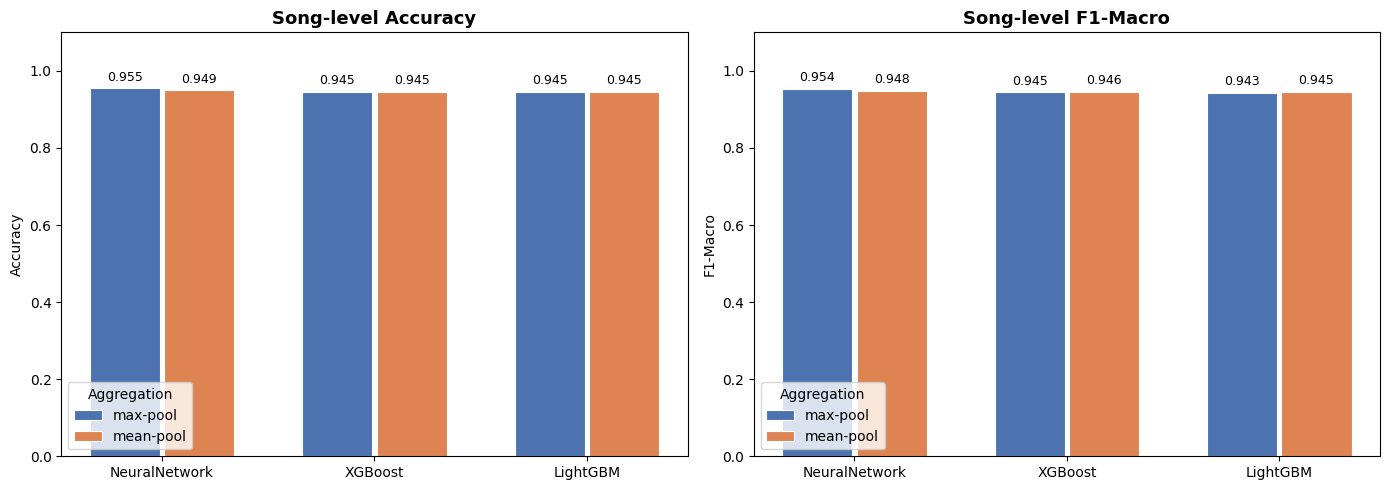

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
metrics = ['Accuracy', 'F1-Macro']

for ax, metric in zip(axes, metrics):
    for i, pooling in enumerate(['max', 'mean']):
        subset = df_results[df_results['Pooling'] == pooling]
        x      = np.arange(len(subset))
        offset = (i - 0.5) * 0.35
        bars   = ax.bar(x + offset, subset[metric], width=0.33,
                        label=f'{pooling}-pool',
                        color=['#4C72B0', '#DD8452'][i],
                        edgecolor='white', linewidth=0.8)
        for bar, val in zip(bars, subset[metric]):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.012,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(np.arange(subset['Model'].nunique()))
    ax.set_xticklabels(df_results['Model'].unique())
    ax.set_title(f'Song-level {metric}', fontsize=13, fontweight='bold')
    ax.set_ylim(0, 1.1)
    ax.set_ylabel(metric)
    ax.legend(title='Aggregation')

plt.tight_layout()
plt.show()


### 7.2 · Per-Genre F1-Score Breakdown

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


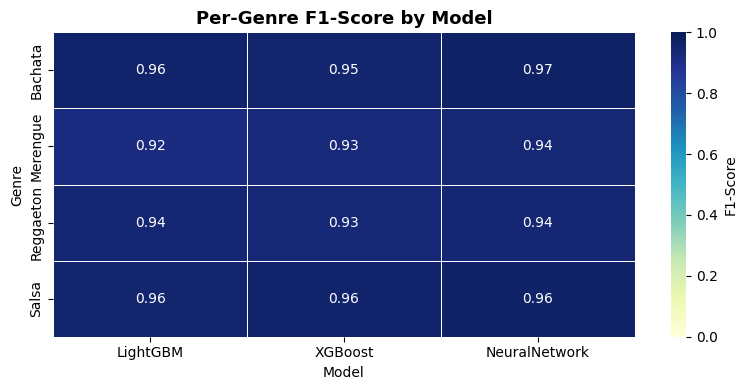


Per-genre F1-Score table:


,LightGBM,XGBoost,NeuralNetwork
Bachata,0.960,0.955,0.969
Merengue,0.915,0.933,0.938
Reggaeton,0.942,0.934,0.945
Salsa,0.957,0.958,0.964


In [12]:
# Build a report for every model and visualise as a heatmap
report_data = {}
for name, model in trained_models.items():
    if name == 'NeuralNetwork':
        probs = model.predict(X_test_scaled, verbose=0)
    else:
        probs = model.predict_proba(X_test_scaled)

    prob_cols = le.classes_.tolist()
    df_preds = pd.DataFrame(probs, columns=prob_cols)
    df_preds['song_id'] = groups_test.values
    df_preds['y_true']  = y_test

    # FIX: separate prob aggregation from label aggregation
    song_probs = df_preds.groupby('song_id')[prob_cols].max()
    song_ytrue = df_preds.groupby('song_id')['y_true'].first()

    y_true = song_ytrue.astype(int)
    y_pred = song_probs.values.argmax(axis=1)

    report = classification_report(y_true, y_pred,
                                   target_names=le.classes_, output_dict=True)
    report_data[name] = {genre: report[genre]['f1-score'] for genre in le.classes_}

df_genre_f1 = pd.DataFrame(report_data)   # rows = genres, cols = models

plt.figure(figsize=(8, max(4, len(le.classes_) * 0.55)))
sns.heatmap(df_genre_f1, annot=True, fmt='.2f', cmap='YlGnBu',
            vmin=0, vmax=1, linewidths=0.5, cbar_kws={'label': 'F1-Score'})
plt.title('Per-Genre F1-Score by Model', fontsize=13, fontweight='bold')
plt.ylabel('Genre')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

print("\nPer-genre F1-Score table:")
display(df_genre_f1.round(3))


### 7.3 · Confusion Matrices

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


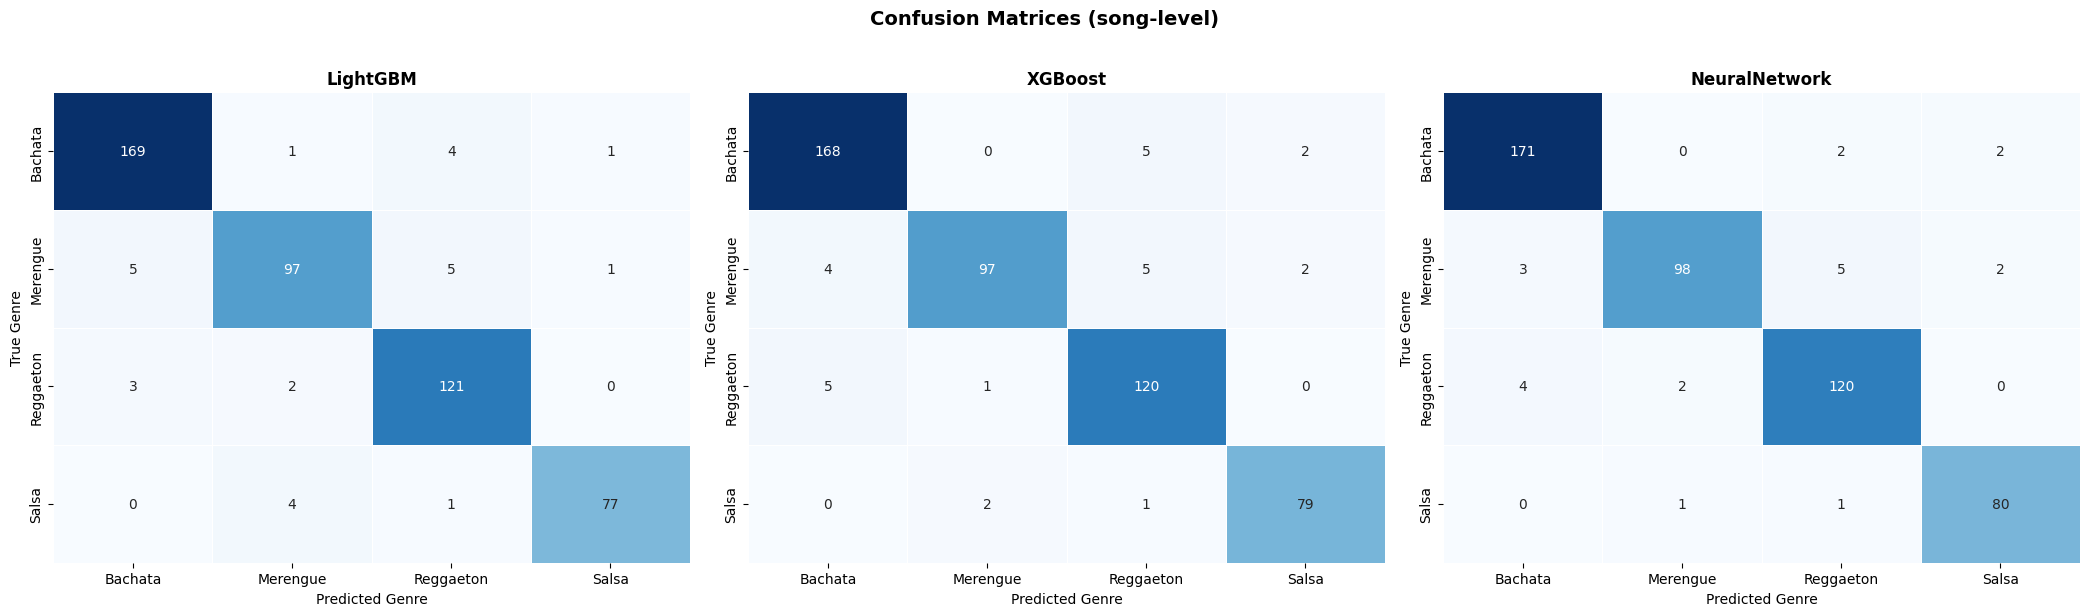

In [13]:
n_models = len(trained_models)
fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 6))
if n_models == 1:
    axes = [axes]   # ensure iterable even for a single model

for ax, (name, model) in zip(axes, trained_models.items()):
    if name == 'NeuralNetwork':
        probs = model.predict(X_test_scaled, verbose=0)
    else:
        probs = model.predict_proba(X_test_scaled)

    prob_cols = le.classes_.tolist()
    df_preds = pd.DataFrame(probs, columns=prob_cols)
    df_preds['song_id'] = groups_test.values
    df_preds['y_true']  = y_test

    # FIX: separate prob aggregation from label aggregation
    song_probs = df_preds.groupby('song_id')[prob_cols].max()
    song_ytrue = df_preds.groupby('song_id')['y_true'].first()

    y_true = song_ytrue.astype(int)
    y_pred = song_probs.values.argmax(axis=1)

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_,
                ax=ax, linewidths=0.4, cbar=False)
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Genre')
    ax.set_ylabel('True Genre')

plt.suptitle('Confusion Matrices (song-level)', fontsize=14, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()


### 7.4 · Optuna Optimisation Curves

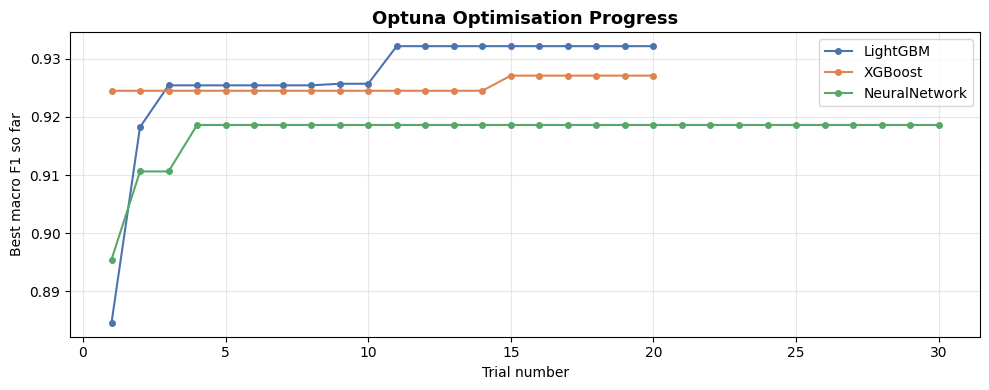

In [14]:
# Show how each model's best objective (macro F1) evolved over trials
fig, ax = plt.subplots(figsize=(10, 4))

for study, label, color in [
    (study_lgb, 'LightGBM',     '#4C72B0'),
    (study_xgb, 'XGBoost',      '#DD8452'),
    (study_nn,  'NeuralNetwork','#55A868'),
]:
    best_vals = [
        max(t.value for t in study.trials[:i+1] if t.value is not None)
        for i in range(len(study.trials))
    ]
    ax.plot(range(1, len(best_vals) + 1), best_vals,
            marker='o', markersize=4, label=label, color=color)

ax.set_xlabel('Trial number')
ax.set_ylabel('Best macro F1 so far')
ax.set_title('Optuna Optimisation Progress', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 7.5 · Feature Importance per Model

Understanding **which features drive each model's decisions** is crucial for interpreting predictions.

| Model | Method | Interpretation |
|-------|--------|----------------|
| **LightGBM** | Built-in `feature_importances_` (gain) | Total gain contributed by each feature across all splits |
| **XGBoost** | Built-in `feature_importances_` (gain) | Same concept, computed by XGBoost's own engine |
| **Neural Network** | Permutation Importance | Measures accuracy drop when a feature's values are randomly shuffled |

> ⚠️ Permutation importance for the Neural Network may take a moment as it re-evaluates the model multiple times.

2026-05-21 13:55:11.603182: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-05-21 13:55:16.716500: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

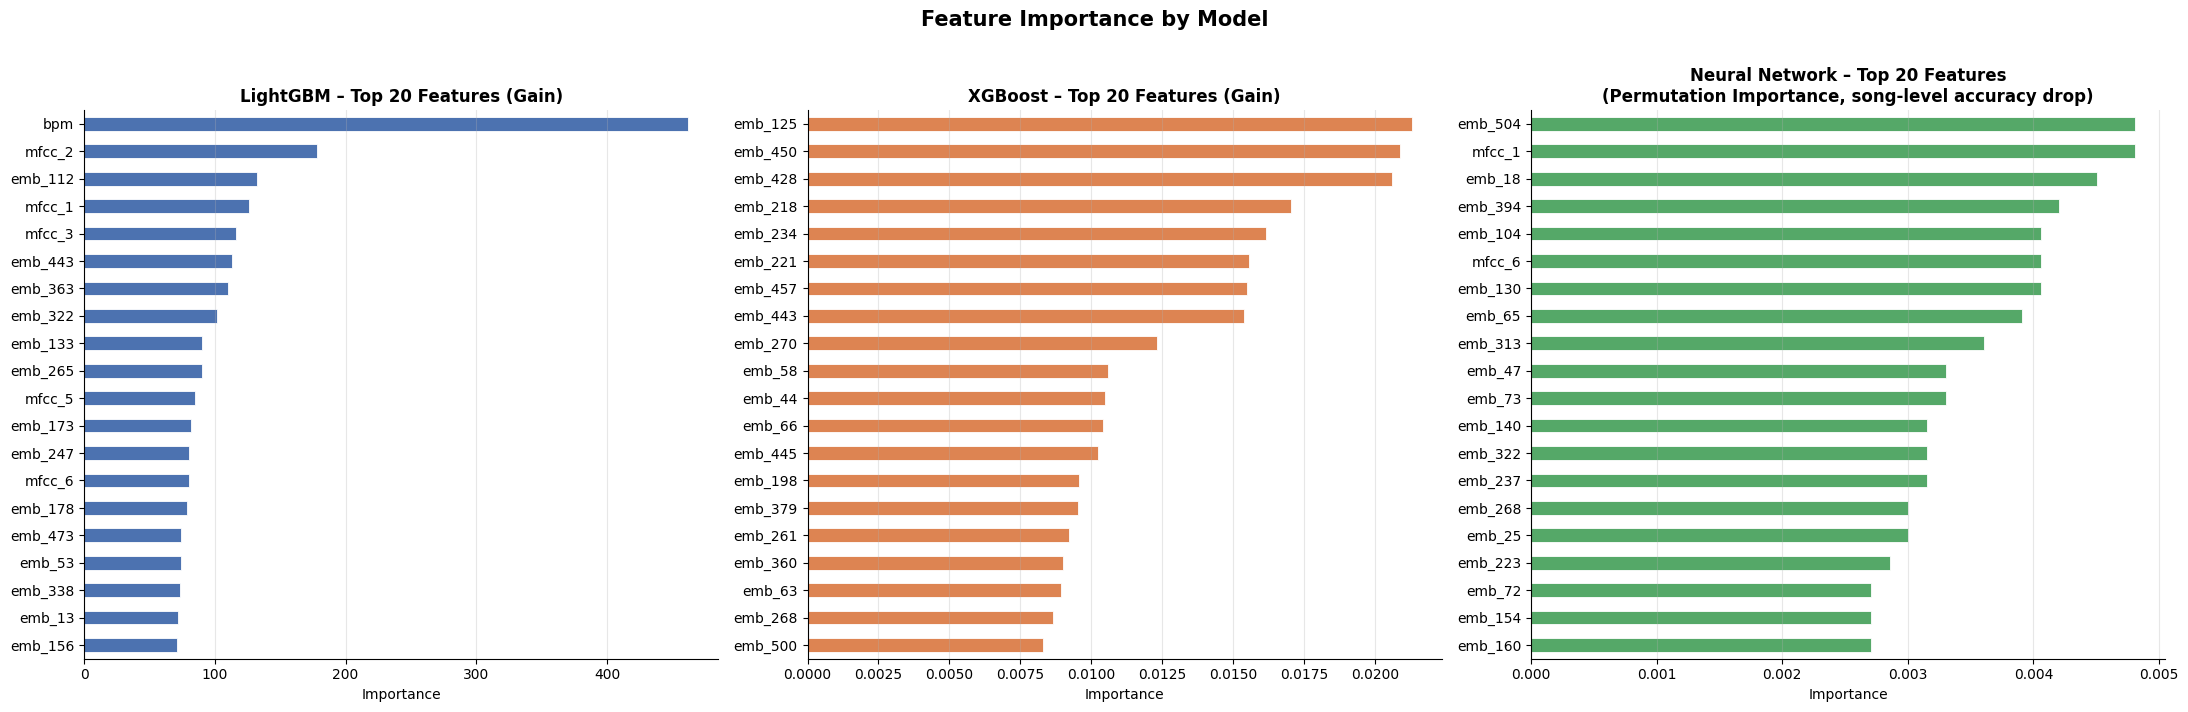


── Top 10 Features per Model ──


,LightGBM (feature),LightGBM (gain),XGBoost (feature),XGBoost (gain),NeuralNet (feature),NeuralNet (Δacc)
0,bpm,462,emb_125,0.0213,emb_504,0.0048
1,mfcc_2,178,emb_450,0.0209,mfcc_1,0.0048
2,emb_112,132,emb_428,0.0206,emb_18,0.0045
3,mfcc_1,126,emb_218,0.0170,emb_394,0.0042
4,mfcc_3,116,emb_234,0.0162,emb_104,0.0041
5,emb_443,113,emb_221,0.0155,mfcc_6,0.0041
6,emb_363,110,emb_457,0.0155,emb_130,0.0041
7,emb_322,102,emb_443,0.0154,emb_65,0.0039
8,emb_133,90,emb_270,0.0123,emb_313,0.0036
9,emb_265,90,emb_58,0.0106,emb_47,0.0033


In [15]:
from sklearn.inspection import permutation_importance

TOP_N      = 20          # how many top features to show per model
BAR_COLOR  = {'LightGBM': '#4C72B0', 'XGBoost': '#DD8452', 'NeuralNetwork': '#55A868'}
feature_names = X.columns.tolist()

# ── Helper: plot a horizontal bar chart of top-N features ─────────────────────
def plot_feature_importance(importances, feature_names, title, color, ax, top_n=TOP_N):
    """Plot the top_n most important features as a horizontal bar chart."""
    fi = pd.Series(importances, index=feature_names).sort_values(ascending=False)
    fi_top = fi.head(top_n).sort_values()          # ascending so largest is at top
    fi_top.plot(kind='barh', ax=ax, color=color, edgecolor='white', linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance')
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# ── LightGBM: built-in gain importance (from the base estimator) ───────────────
lgb_imp = best_lgb_cal.estimator.feature_importances_
plot_feature_importance(
    lgb_imp, feature_names,
    f'LightGBM – Top {TOP_N} Features (Gain)',
    BAR_COLOR['LightGBM'], axes[0]
)

# ── XGBoost: built-in gain importance (from the base estimator) ───────────────
xgb_imp = best_xgb_cal.estimator.feature_importances_
plot_feature_importance(
    xgb_imp, feature_names,
    f'XGBoost – Top {TOP_N} Features (Gain)',
    BAR_COLOR['XGBoost'], axes[1]
)

# ── Neural Network: permutation importance at SONG level ──────────────────────
# Fragment-level permutation importance can differ from song-level accuracy.
# We aggregate to song level before scoring, matching the evaluation protocol.
prob_cols_nn = le.classes_.tolist()

def nn_song_level_score(X_frag, y_frag_ignored):
    """Score best_nn at song level on the test set (groups_test is captured from outer scope)."""
    probs = best_nn.predict(X_frag, verbose=0)
    df_p  = pd.DataFrame(probs, columns=prob_cols_nn)
    df_p['song_id'] = groups_test.values
    df_p['y_true']  = y_test
    song_probs = df_p.groupby('song_id')[prob_cols_nn].max()
    song_ytrue = df_p.groupby('song_id')['y_true'].first().astype(int)
    y_pred = song_probs.values.argmax(axis=1)
    return accuracy_score(song_ytrue.values, y_pred)

from sklearn.base import BaseEstimator

class KerasSklearnWrapper(BaseEstimator):
    """Thin sklearn-compatible wrapper around the trained Keras model."""
    def __init__(self, keras_model):
        self.keras_model = keras_model
        self.classes_ = np.arange(num_classes)

    def fit(self, X, y):
        return self

    def predict(self, X):
        return self.keras_model.predict(X, verbose=0).argmax(axis=1)

    def score(self, X, y):
        """Song-level accuracy — matches the notebook's evaluation protocol."""
        return nn_song_level_score(X, y)

nn_wrapper = KerasSklearnWrapper(best_nn)
# FIX: use SEED (not 42) for consistency; scoring is now at song level
perm_result = permutation_importance(
    nn_wrapper, X_test_scaled, y_test,
    n_repeats=5,
    random_state=SEED,
    scoring='accuracy'
)
plot_feature_importance(
    perm_result.importances_mean, feature_names,
    f'Neural Network – Top {TOP_N} Features\n(Permutation Importance, song-level accuracy drop)',
    BAR_COLOR['NeuralNetwork'], axes[2]
)

plt.suptitle('Feature Importance by Model', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# ── Summary table: top-10 features per model side by side ─────────────────────
print("\n── Top 10 Features per Model ──")
top10_lgb = pd.Series(lgb_imp, index=feature_names).sort_values(ascending=False).head(10)
top10_xgb = pd.Series(xgb_imp, index=feature_names).sort_values(ascending=False).head(10)
top10_nn  = pd.Series(perm_result.importances_mean, index=feature_names).sort_values(ascending=False).head(10)

df_top10 = pd.DataFrame({
    'LightGBM (feature)' : top10_lgb.index,
    'LightGBM (gain)'    : top10_lgb.values.round(1),
    'XGBoost (feature)'  : top10_xgb.index,
    'XGBoost (gain)'     : top10_xgb.values.round(4),
    'NeuralNet (feature)': top10_nn.index,
    'NeuralNet (Δacc)'   : top10_nn.values.round(4),
})
display(df_top10)


## 8 · Error Analysis – High-Confidence Mistakes

The most revealing failures are the ones where the model was **very sure but wrong**.
These songs deserve special attention: they may be mislabelled in the dataset, genuinely
ambiguous, or reveal a systematic weakness of the model.

We filter predictions where:
- **Predicted ≠ True genre** (wrong prediction)
- **Confidence ≥ 80 %** (the model was very confident)


In [16]:
# Pick the best base model + pooling strategy for error analysis
best_model_name = df_results[df_results['Model'] != 'Stacking'].iloc[0]['Model']
best_model        = trained_models[best_model_name]
print(f"Best model: {best_model_name}  |  Pooling: {BEST_POOLING}")

# Fragment-level probabilities → song-level aggregation
if best_model_name == 'NeuralNetwork':
    probs = best_model.predict(X_test_scaled, verbose=0)
else:
    probs = best_model.predict_proba(X_test_scaled)

prob_cols = le.classes_.tolist()
df_preds  = pd.DataFrame(probs, columns=prob_cols)
df_preds['song_id'] = groups_test.values
df_preds['y_true']  = y_test

# FIX: separate prob aggregation from label aggregation in both pooling modes
if BEST_POOLING == 'max':
    song_probs = df_preds.groupby('song_id')[prob_cols].max()
else:
    song_probs = df_preds.groupby('song_id')[prob_cols].mean()
song_ytrue = df_preds.groupby('song_id')['y_true'].first()  # label is constant per song
song_preds = song_probs.copy()
song_preds['y_true'] = song_ytrue

y_song_true     = song_preds['y_true'].astype(int)
probs_array     = song_preds[prob_cols].values
y_song_pred_idx = probs_array.argmax(axis=1)
confidence      = probs_array.max(axis=1)

df_analysis = pd.DataFrame({
    'song_id'        : song_preds.index,
    'true_genre'     : le.inverse_transform(y_song_true),
    'predicted_genre': le.inverse_transform(y_song_pred_idx),
    'confidence'     : confidence,
})

# Attach track / artist metadata if available
meta_cols = [c for c in ['track', 'artist'] if c in df.columns]
if meta_cols:
    metadata    = df[['song_id'] + meta_cols].drop_duplicates().set_index('song_id')
    df_analysis = df_analysis.join(metadata, on='song_id')

col_order   = ['song_id'] + meta_cols + ['true_genre', 'predicted_genre', 'confidence']
df_analysis = df_analysis[col_order]

# High-confidence errors
confidence_threshold = 0.80
high_conf_errors  = df_analysis[
    (df_analysis['true_genre'] != df_analysis['predicted_genre']) &
    (df_analysis['confidence'] >= confidence_threshold)
].sort_values('confidence', ascending=False)

print(f"Songs wrongly predicted with ≥{confidence_threshold*100:.0f}% confidence: {len(high_conf_errors)}")
display(high_conf_errors)


Best model: NeuralNetwork  |  Pooling: max
Songs wrongly predicted with ≥80% confidence: 14


,song_id,true_genre,predicted_genre,confidence
312,4vj6sWvmBLMhoF8AWQSeHX,Bachata,Salsa,0.996779
425,6gXGdQp8Zr2UR7sj1QoEj1,Merengue,Salsa,0.990922
357,5ds1Hh3lo4JUF2vflqyayK,Salsa,Reggaeton,0.953424
250,3v8rMwnAtyeFSICYNceCEX,Merengue,Reggaeton,0.953177
185,2uyCcoHiRGttV0uXaNXGB1,Salsa,Merengue,0.950515
79,1HX2dU4tr8PfvS648S0Xtz,Bachata,Salsa,0.929117
38,0cWpdcpOicoAtl0kpI73GL,Reggaeton,Bachata,0.915953
316,51FvjPEGKq2zByeeEQ43V9,Merengue,Reggaeton,0.905589
374,5tk6YO6cLavzqoGUEl9KxQ,Bachata,Reggaeton,0.901059
307,4tzN2SHcqhccWmXDiG9U9D,Merengue,Reggaeton,0.893922


### 8.0 · Ambiguity Detection — Multi-Genre Songs

Some songs genuinely belong to more than one genre (e.g. *Volví* by Aventura & Bad Bunny
is simultaneously bachata and reggaeton). Forcing a single label on these is both wrong
and unfair to the model — it can only predict what its training labels say.

**Strategy (post-processing, no retraining needed):**

After song-level probability aggregation, instead of always taking `argmax`, we check
whether two genres are *close enough* to each other at the top:

```
ambiguity_gap = P(top-1 genre) − P(top-2 genre)
```

If `ambiguity_gap < AMBIGUITY_THRESHOLD`, the song is flagged as
**ambiguous: genre_A / genre_B** instead of committing to a single label.

| Decision | Condition |
|----------|-----------|
| Single label | `gap ≥ AMBIGUITY_THRESHOLD` — model is confident |
| Ambiguous (top-2) | `gap < AMBIGUITY_THRESHOLD` — two genres are close |

This is **honest reporting**: we trade a small drop in hard-accuracy for a large gain
in real-world usefulness — a user can decide between the two candidate genres.

In evaluation we count an ambiguous prediction as **correct** if the true label
appears in the top-2 (`top2_accuracy`).

> ℹ️ The threshold is tuned on the **validation set** to maximise
> `top2_accuracy − ambiguity_rate` — we want to catch genuinely ambiguous songs
> without flagging everything as ambiguous.


Tuning results (val set):
 threshold  top2_accuracy  ambiguity_rate  score
      0.05         0.9592          0.0204 0.9388
      0.10         0.9643          0.0357 0.9286
      0.15         0.9694          0.0459 0.9235
      0.20         0.9694          0.0663 0.9031
      0.25         0.9796          0.0969 0.8827
      0.30         0.9796          0.1173 0.8622

✅ Selected AMBIGUITY_THRESHOLD = 0.05

Test set results (threshold = 0.05):
  Hard accuracy  (argmax only) : 0.9552
  Top-2 accuracy (ambig aware) : 0.9613
  Ambiguous songs flagged      : 10 / 491 (2.0%)

Ambiguous songs:
               song_id true_genre            predicted   gap  p_top1  p_top2
0H6hDn1jaralA0JtSsW5DU    Bachata      Bachata / Salsa 0.001   0.736   0.735
5mipeT4dEOTg9Eg5b9joME   Merengue     Merengue / Salsa 0.009   0.983   0.974
7sGvZg5wfTBoWhBNIwDmaF   Merengue     Salsa / Merengue 0.009   0.606   0.598
1imNlcgGvoEAtmhCeGCjcn    Bachata  Bachata / Reggaeton 0.014   0.463   0.449
7iqssRzxNq4MgSLDCHoGWt

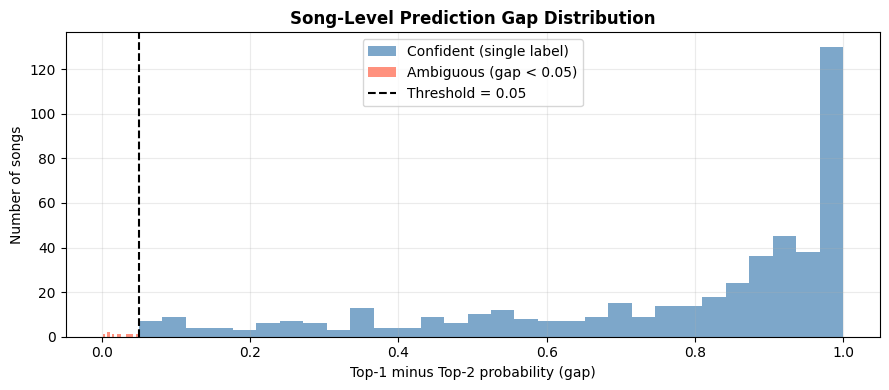

In [17]:
# ── Ambiguity threshold tuning on val set ────────────────────────────────────
AMBIGUITY_THRESHOLD_CANDIDATES = np.arange(0.05, 0.35, 0.05)
best_ambig_model_name = df_results[df_results['Model'] != 'Stacking'].iloc[0]['Model']
best_ambig_model      = trained_models[best_ambig_model_name]

if best_ambig_model_name == 'NeuralNetwork':
    val_probs_raw = best_ambig_model.predict(X_val_scaled, verbose=0)
else:
    val_probs_raw = best_ambig_model.predict_proba(X_val_scaled)

prob_cols = le.classes_.tolist()
df_vp = pd.DataFrame(val_probs_raw, columns=prob_cols)
df_vp['song_id'] = groups_val.values
df_vp['y_true']  = y_val

if BEST_POOLING == 'max':
    val_song_probs = df_vp.groupby('song_id')[prob_cols].max()
else:
    val_song_probs = df_vp.groupby('song_id')[prob_cols].mean()
val_song_ytrue = df_vp.groupby('song_id')['y_true'].first().astype(int)

val_probs_arr    = val_song_probs.values
val_sorted_probs = np.sort(val_probs_arr, axis=1)[:, ::-1]  # descending
val_gaps         = val_sorted_probs[:, 0] - val_sorted_probs[:, 1]
val_top1         = val_probs_arr.argmax(axis=1)
val_top2         = np.argsort(val_probs_arr, axis=1)[:, -2]
val_ytrue        = val_song_ytrue.values

tuning_rows = []
for thresh in AMBIGUITY_THRESHOLD_CANDIDATES:
    ambiguous_mask = val_gaps < thresh
    # Top-2 accuracy: correct if true label is top-1 OR top-2
    top2_correct = (val_ytrue == val_top1) | (ambiguous_mask & (val_ytrue == val_top2))
    top2_acc     = top2_correct.mean()
    ambig_rate   = ambiguous_mask.mean()
    score        = top2_acc - ambig_rate          # reward accuracy, penalise over-flagging
    tuning_rows.append({'threshold': round(thresh, 2), 'top2_accuracy': round(top2_acc, 4),
                        'ambiguity_rate': round(ambig_rate, 4), 'score': round(score, 4)})

df_tuning = pd.DataFrame(tuning_rows)
AMBIGUITY_THRESHOLD = df_tuning.loc[df_tuning['score'].idxmax(), 'threshold']
print(f"Tuning results (val set):")
print(df_tuning.to_string(index=False))
print(f"\n✅ Selected AMBIGUITY_THRESHOLD = {AMBIGUITY_THRESHOLD}")

# ── Apply ambiguity detection to test set ─────────────────────────────────────
if best_ambig_model_name == 'NeuralNetwork':
    test_probs_raw = best_ambig_model.predict(X_test_scaled, verbose=0)
else:
    test_probs_raw = best_ambig_model.predict_proba(X_test_scaled)

df_tp = pd.DataFrame(test_probs_raw, columns=prob_cols)
df_tp['song_id'] = groups_test.values
df_tp['y_true']  = y_test

if BEST_POOLING == 'max':
    test_song_probs = df_tp.groupby('song_id')[prob_cols].max()
else:
    test_song_probs = df_tp.groupby('song_id')[prob_cols].mean()
test_song_ytrue = df_tp.groupby('song_id')['y_true'].first().astype(int)

test_probs_arr    = test_song_probs.values
test_sorted_probs = np.sort(test_probs_arr, axis=1)[:, ::-1]
test_gaps         = test_sorted_probs[:, 0] - test_sorted_probs[:, 1]
test_top1_idx     = test_probs_arr.argmax(axis=1)
test_top2_idx     = np.argsort(test_probs_arr, axis=1)[:, -2]
test_ytrue        = test_song_ytrue.values

ambiguous_mask_test = test_gaps < AMBIGUITY_THRESHOLD
test_top1_labels    = le.inverse_transform(test_top1_idx)
test_top2_labels    = le.inverse_transform(test_top2_idx)

predicted_label = np.where(
    ambiguous_mask_test,
    np.array([f"{a} / {b}" for a, b in zip(test_top1_labels, test_top2_labels)]),
    test_top1_labels
)
true_label = le.inverse_transform(test_ytrue)

# Top-2 accuracy on test set
top2_correct_test = (test_ytrue == test_top1_idx) | \
                    (ambiguous_mask_test & (test_ytrue == test_top2_idx))
hard_correct_test = (test_ytrue == test_top1_idx)

print(f"\nTest set results (threshold = {AMBIGUITY_THRESHOLD}):")
print(f"  Hard accuracy  (argmax only) : {hard_correct_test.mean():.4f}")
print(f"  Top-2 accuracy (ambig aware) : {top2_correct_test.mean():.4f}")
print(f"  Ambiguous songs flagged      : {ambiguous_mask_test.sum()} / {len(ambiguous_mask_test)} "
      f"({ambiguous_mask_test.mean()*100:.1f}%)")

# Display ambiguous songs
df_ambig = pd.DataFrame({
    'song_id'        : test_song_probs.index,
    'true_genre'     : true_label,
    'predicted'      : predicted_label,
    'gap'            : test_gaps.round(3),
    'p_top1'         : test_sorted_probs[:, 0].round(3),
    'p_top2'         : test_sorted_probs[:, 1].round(3),
})
df_ambig_flagged = df_ambig[ambiguous_mask_test].sort_values('gap')
print(f"\nAmbiguous songs:")
print(df_ambig_flagged.to_string(index=False))

# ── Visualise gap distribution ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(test_gaps[~ambiguous_mask_test], bins=30, alpha=0.7,
        color='steelblue', label='Confident (single label)')
ax.hist(test_gaps[ambiguous_mask_test],  bins=15, alpha=0.7,
        color='tomato', label=f'Ambiguous (gap < {AMBIGUITY_THRESHOLD})')
ax.axvline(AMBIGUITY_THRESHOLD, color='black', linestyle='--', lw=1.5,
           label=f'Threshold = {AMBIGUITY_THRESHOLD}')
ax.set_xlabel('Top-1 minus Top-2 probability (gap)')
ax.set_ylabel('Number of songs')
ax.set_title('Song-Level Prediction Gap Distribution', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
2026-05-21 14:03:49.436907: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


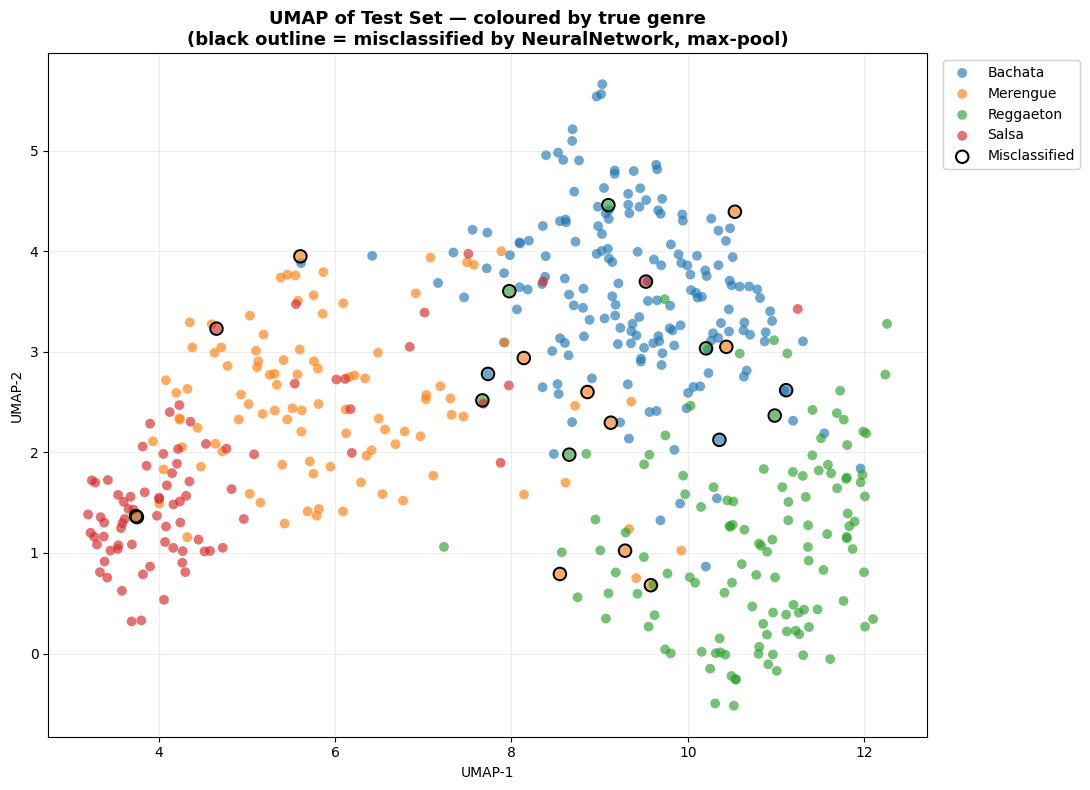

Model used for error overlay: NeuralNetwork (max-pool)
Misclassified songs: 22 / 491


In [18]:
import umap

# ── 1. Reduce to 2D on the test fragment set ──────────────────────────────────
reducer = umap.UMAP(n_components=2, random_state=SEED, n_neighbors=15, min_dist=0.1)
X_test_2d = reducer.fit_transform(X_test_scaled)

# ── 2. Aggregate fragment 2D coords to song level ─────────────────────────────
df_umap = pd.DataFrame(X_test_2d, columns=['u1', 'u2'])
df_umap['song_id'] = groups_test.values
df_umap['y_true']  = le.inverse_transform(y_test)

song_umap = df_umap.groupby('song_id')[['u1', 'u2']].mean()
song_umap['genre'] = df_umap.groupby('song_id')['y_true'].first()

# ── 3. Compute song-level predictions inline (df_analysis built in § 8) ───────
# We replicate the aggregation here so this cell can run independently.
_best_name  = df_results[df_results['Model'] != 'Stacking'].iloc[0]['Model']
_best_model = trained_models[_best_name]
_prob_cols  = le.classes_.tolist()

if _best_name == 'NeuralNetwork':
    _probs = _best_model.predict(X_test_scaled, verbose=0)
else:
    _probs = _best_model.predict_proba(X_test_scaled)

_df_p = pd.DataFrame(_probs, columns=le.classes_)
_df_p['song_id'] = groups_test.values
_df_p['y_true']  = y_test

if BEST_POOLING == 'max':
    _sp = _df_p.groupby('song_id')[_prob_cols].max()
else:
    _sp = _df_p.groupby('song_id')[_prob_cols].mean()
_sp['y_true'] = _df_p.groupby('song_id')['y_true'].first()

_y_true_song = _sp['y_true'].astype(int)
_y_pred_song = _sp[_prob_cols].values.argmax(axis=1)

_song_correct = pd.Series(
    le.inverse_transform(_y_true_song) == le.inverse_transform(_y_pred_song),
    index=_sp.index,
    name='correct'
)

song_umap = song_umap.join(_song_correct)

# ── 4. Plot ───────────────────────────────────────────────────────────────────
genres      = sorted(song_umap['genre'].unique())
palette     = sns.color_palette('tab10', n_colors=len(genres))
genre_color = dict(zip(genres, palette))

fig, ax = plt.subplots(figsize=(11, 8))

for genre, grp in song_umap.groupby('genre'):
    ax.scatter(grp['u1'], grp['u2'],
               color=genre_color[genre], label=genre,
               alpha=0.65, s=50, edgecolors='none')

errors_umap = song_umap[song_umap['correct'] == False]
ax.scatter(errors_umap['u1'], errors_umap['u2'],
           facecolors='none', edgecolors='black',
           linewidths=1.5, s=80, label='Misclassified', zorder=5)

ax.set_title(
    f'UMAP of Test Set — coloured by true genre\n'
    f'(black outline = misclassified by {_best_name}, {BEST_POOLING}-pool)',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('UMAP-1')
ax.set_ylabel('UMAP-2')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', framealpha=0.9)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Model used for error overlay: {_best_name} ({BEST_POOLING}-pool)")
print(f"Misclassified songs: {len(errors_umap)} / {len(song_umap)}")


### 8.1 · Which genre pairs are most confused?

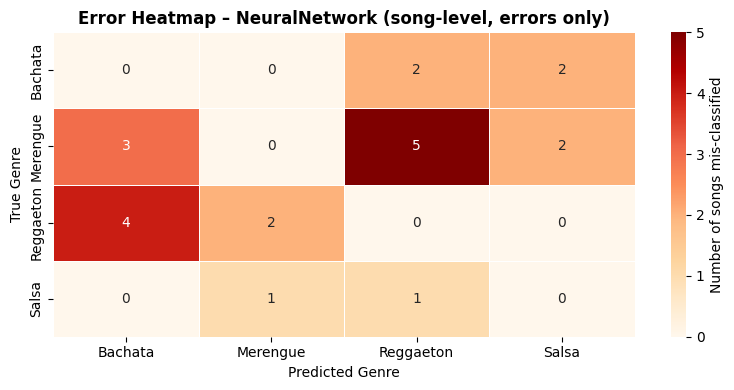

In [19]:
# Stacked bar: for each true genre, show how often it gets confused with each predicted genre
errors_only = df_analysis[df_analysis['true_genre'] != df_analysis['predicted_genre']]
confusion_pairs = (errors_only.groupby(['true_genre', 'predicted_genre'])
                               .size()
                               .reset_index(name='count')
                               .sort_values('count', ascending=False))

# Pivot for a heatmap
pivot = confusion_pairs.pivot(index='true_genre', columns='predicted_genre', values='count').fillna(0)

plt.figure(figsize=(8, max(4, len(le.classes_) * 0.55)))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='OrRd',
            linewidths=0.5, cbar_kws={'label': 'Number of songs mis-classified'})
plt.title(f'Error Heatmap – {best_model_name} (song-level, errors only)',
          fontsize=12, fontweight='bold')
plt.xlabel('Predicted Genre')
plt.ylabel('True Genre')
plt.tight_layout()
plt.show()


### 8.4 · Fragment Consistency Analysis

Within a single song, how consistent are the model's predictions across fragments?  
High **prediction entropy** across fragments signals genuinely ambiguous songs —  
useful for surfacing mislabelled tracks and for building richer meta-model features.

| Metric | Meaning |
|--------|---------|
| **Pred entropy** | Shannon entropy of per-genre mean probability vector — high = uncertain |
| **Top-1 agree rate** | Fraction of fragments that agree with the song-level top-1 class |
| **Frag std** | Mean std of per-genre probabilities across fragments — high = inconsistent |


Fragment consistency summary (NeuralNetwork, song-level):


agree_rate                                            pred_entropy  \
             count   mean    std    min  25%    50%  75%  max        count   
correct                                                                      
False         25.0  0.680  0.235  0.333  0.5  0.667  1.0  1.0         25.0   
True         466.0  0.939  0.152  0.333  1.0  1.000  1.0  1.0        466.0   

                ...               frag_std                                     \
          mean  ...    75%    max    count   mean    std    min    25%    50%   
correct         ...                                                             
False    0.907  ...  1.081  1.224     24.0  0.162  0.093  0.023  0.071  0.147   
True     0.397  ...  0.641  1.350    455.0  0.060  0.073  0.000  0.006  0.028   

                       
           75%    max  
correct                
False    0.240  0.336  
True     0.092  0.345  

[2 rows x 24 columns]


Top 10 most inconsistent songs (highest prediction entropy):


,song_id,true_genre,pred_genre,correct,n_fragments,agree_rate,pred_entropy,frag_std
470,7fZJWsOEdr8aP8okxyTBGd,Reggaeton,Reggaeton,True,3,0.333,1.3503,0.3166
359,5fq4jxlqyjAVFLOB0lZIdT,Merengue,Merengue,True,3,0.667,1.2819,0.1357
436,6stYbAJgTszHAHZMPxWWCY,Reggaeton,Reggaeton,True,3,0.333,1.2643,0.1913
360,5hBx4OMn1KNIW2T0NiTaB3,Bachata,Bachata,True,3,0.333,1.2473,0.3023
154,2TVmncTGqL39BnJ3wX1VDj,Bachata,Reggaeton,False,3,0.333,1.2238,0.2448
308,4uJMySBZrXhLThpLHwdE30,Merengue,Merengue,True,2,0.500,1.2097,0.2241
172,2ksdEWTaAZ0XWvoOyk5PQf,Reggaeton,Reggaeton,True,2,0.500,1.1678,0.2416
463,7L3Z21b1wuEO1Os5xgSE6G,Bachata,Bachata,True,2,0.500,1.1616,0.0974
279,4W6za66pgH7QBbeiU9kS1v,Bachata,Bachata,True,3,1.000,1.1606,0.1319
106,1imNlcgGvoEAtmhCeGCjcn,Bachata,Reggaeton,False,3,0.667,1.1570,0.0447


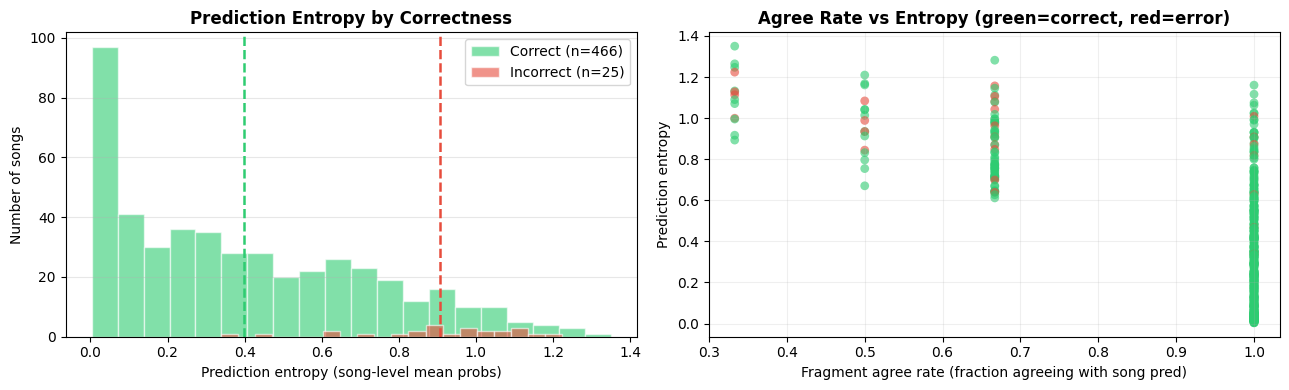


💡 Songs with high entropy AND low agree rate are the hardest cases — candidates for manual review or multi-label annotation.


In [20]:
# ── Fragment consistency per song on the test set ─────────────────────────
_cons_name  = df_results[df_results['Model'] != 'Stacking'].iloc[0]['Model']
_cons_model = trained_models[_cons_name]

if _cons_name == 'NeuralNetwork':
    _frag_probs = _cons_model.predict(X_test_scaled, verbose=0)
else:
    _frag_probs = _cons_model.predict_proba(X_test_scaled)

_prob_cols = le.classes_.tolist()
df_cons = pd.DataFrame(_frag_probs, columns=_prob_cols)
df_cons['song_id'] = groups_test.values
df_cons['y_true']  = y_test
df_cons['frag_pred'] = _frag_probs.argmax(axis=1)

def _entropy(p_row):
    p = np.array(p_row)
    p = p[p > 0]
    return float(-np.sum(p * np.log(p + 1e-12)))

consistency_rows = []
for sid, grp in df_cons.groupby('song_id'):
    mean_probs   = grp[_prob_cols].mean().values
    song_pred    = mean_probs.argmax()
    agree_rate   = (grp['frag_pred'] == song_pred).mean()
    frag_std     = grp[_prob_cols].std().mean()          # mean std across genres and fragments
    pred_entropy = _entropy(mean_probs)
    true_label   = grp['y_true'].iloc[0]
    consistency_rows.append({
        'song_id'      : sid,
        'true_genre'   : le.inverse_transform([true_label])[0],
        'pred_genre'   : le.inverse_transform([song_pred])[0],
        'correct'      : true_label == song_pred,
        'n_fragments'  : len(grp),
        'agree_rate'   : round(agree_rate, 3),
        'pred_entropy' : round(pred_entropy, 4),
        'frag_std'     : round(frag_std, 4),
    })

df_cons_songs = pd.DataFrame(consistency_rows).sort_values('pred_entropy', ascending=False)

# ── Summary stats by correctness ──────────────────────────────────────────────
print(f"Fragment consistency summary ({_cons_name}, song-level):")
display(df_cons_songs.groupby('correct')[['agree_rate','pred_entropy','frag_std']]
        .describe().round(3))

# ── Top-10 most inconsistent songs (highest entropy) ─────────────────────────
print("\nTop 10 most inconsistent songs (highest prediction entropy):")
display(df_cons_songs.head(10))

# ── Visualise entropy distribution by correctness ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for is_correct, color, label in [(True, '#2ecc71', 'Correct'), (False, '#e74c3c', 'Incorrect')]:
    sub = df_cons_songs[df_cons_songs['correct'] == is_correct]
    axes[0].hist(sub['pred_entropy'], bins=20, alpha=0.6, color=color,
                 label=f'{label} (n={len(sub)})', edgecolor='white')
    axes[0].axvline(sub['pred_entropy'].mean(), color=color, linestyle='--', lw=1.8)
axes[0].set_xlabel('Prediction entropy (song-level mean probs)')
axes[0].set_ylabel('Number of songs')
axes[0].set_title('Prediction Entropy by Correctness', fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# ── Entropy vs agree-rate scatter ─────────────────────────────────────────────
colors_scatter = ['#2ecc71' if c else '#e74c3c' for c in df_cons_songs['correct']]
axes[1].scatter(df_cons_songs['agree_rate'], df_cons_songs['pred_entropy'],
                c=colors_scatter, alpha=0.6, s=40, edgecolors='none')
axes[1].set_xlabel('Fragment agree rate (fraction agreeing with song pred)')
axes[1].set_ylabel('Prediction entropy')
axes[1].set_title('Agree Rate vs Entropy (green=correct, red=error)', fontweight='bold')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print("\n💡 Songs with high entropy AND low agree rate are the hardest cases — "
      "candidates for manual review or multi-label annotation.")


### 8.2 · Confidence Distribution: Correct vs Incorrect Predictions

Models that are well-calibrated should be **more confident when they are right**.  
This chart compares the distribution of prediction confidence scores between
correctly and incorrectly classified songs.


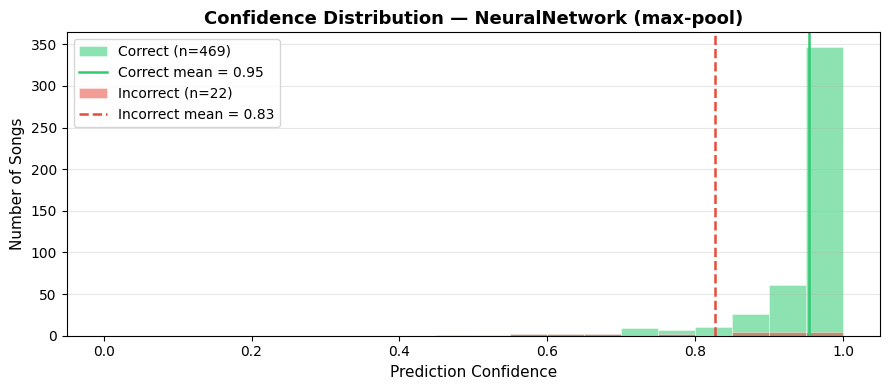


Confidence summary:
           count   mean    std    min    25%    50%    75%    max
correct                                                          
Incorrect   22.0  0.827  0.140  0.550  0.704  0.891  0.926  0.997
Correct    469.0  0.954  0.074  0.463  0.947  0.980  0.996  1.000


In [21]:
df_analysis['correct'] = df_analysis['true_genre'] == df_analysis['predicted_genre']

fig, ax = plt.subplots(figsize=(9, 4))

for label, color, ls in [
    ('Correct',   '#2ecc71', '-'),
    ('Incorrect', '#e74c3c', '--'),
]:
    subset = df_analysis[df_analysis['correct'] == (label == 'Correct')]['confidence']
    ax.hist(subset, bins=20, range=(0, 1),
            alpha=0.55, color=color, label=f'{label} (n={len(subset)})',
            edgecolor='white', linewidth=0.5)
    ax.axvline(subset.mean(), color=color, linestyle=ls, linewidth=1.8,
               label=f'{label} mean = {subset.mean():.2f}')

ax.set_xlabel('Prediction Confidence', fontsize=11)
ax.set_ylabel('Number of Songs', fontsize=11)
ax.set_title(f'Confidence Distribution — {best_model_name} ({BEST_POOLING}-pool)',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nConfidence summary:")
print(df_analysis.groupby('correct')['confidence']
      .describe().round(3).rename(index={True: 'Correct', False: 'Incorrect'}))


### 8.3 · Stacking Ensemble

A **stacking ensemble** trains a lightweight meta-model on the probability outputs of the
three base models.  
The meta-model learns which base model to trust more for each genre combination.

| Layer | Input | Output |
|-------|-------|--------|
| Base models | Fragment features (scaled) | Per-genre probability vectors |
| Song aggregation | Fragment probabilities | Song-level probability vectors |
| Meta-model (LogReg) | Concatenated song-level probs | Final genre prediction |

> ✅ **Leakage-free OOF design**: the meta-model is trained on **out-of-fold (OOF)**
> predictions generated via 5-fold cross-validation on the training set.
> This means the meta-model never trains on data its base models have already seen,
> eliminating the in-distribution bias present in naive stacking.


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# ── Helper: aggregate fragment probabilities to song level ────────────────────
def song_level_probs(model_name, model, X_frag, y_frag, groups_frag, pooling=BEST_POOLING):
    """Return song_ids, (n_songs,) true-label array, and (n_songs, n_classes) prob matrix."""
    if model_name == 'NeuralNetwork':
        probs = model.predict(X_frag, verbose=0)
    else:
        probs = model.predict_proba(X_frag)

    df_p = pd.DataFrame(probs, columns=le.classes_)
    df_p['song_id'] = groups_frag.values
    df_p['y_true']  = y_frag

    prob_cols = le.classes_.tolist()
    if pooling == 'max':
        agg_probs = df_p.groupby('song_id')[prob_cols].max()
    else:
        agg_probs = df_p.groupby('song_id')[prob_cols].mean()
    agg_ytrue = df_p.groupby('song_id')['y_true'].first()
    agg = agg_probs.copy()
    agg['y_true'] = agg_ytrue

    y_song   = agg['y_true'].astype(int).values
    p_song   = agg[prob_cols].values
    song_ids = agg.index.values
    return song_ids, y_song, p_song


# ── 1. Out-of-fold (OOF) song-level probs on the training set ─────────────────
# StratifiedGroupKFold prevents song-level leakage in OOF predictions.
y_train_orig        = y_train
groups_train_orig   = groups_train

df_train_meta = pd.DataFrame({'song_id': groups_train_orig.values, 'y_true': y_train_orig})
song_label_map = df_train_meta.drop_duplicates('song_id').set_index('song_id')['y_true']
train_song_ids = song_label_map.index.values
y_train_song   = song_label_map.values

n_train_songs  = len(train_song_ids)
n_models_base  = len([k for k in trained_models if k != 'Stacking'])
X_stack_train  = np.zeros((n_train_songs, n_models_base * num_classes))

sgkf_stack = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
song_to_idx = {sid: i for i, sid in enumerate(train_song_ids)}

for fold, (f_train, f_val) in enumerate(
        sgkf_stack.split(X_train_orig_scaled, y_train_orig, groups=groups_train_orig)):
    X_f_val = X_train_orig_scaled[f_val]
    g_f_val = groups_train_orig.iloc[f_val]

    col_offset = 0
    for name, model in trained_models.items():
        if name == 'Stacking':
            continue
        if name == 'NeuralNetwork':
            probs_fold = model.predict(X_f_val, verbose=0)
        else:
            probs_fold = model.predict_proba(X_f_val)

        df_fold = pd.DataFrame(probs_fold, columns=le.classes_)
        df_fold['song_id'] = g_f_val.values

        if BEST_POOLING == 'max':
            agg_fold = df_fold.groupby('song_id')[le.classes_.tolist()].max()
        else:
            agg_fold = df_fold.groupby('song_id')[le.classes_.tolist()].mean()

        for sid, row in agg_fold.iterrows():
            if sid in song_to_idx:
                X_stack_train[song_to_idx[sid], col_offset:col_offset + num_classes] = row.values

        col_offset += num_classes

    print(f"  Fold {fold + 1}/5 done")

print(f"OOF stacking matrix shape: {X_stack_train.shape}")


# ── 2. Test-set song-level probs from each base model ─────────────────────────
test_ids, y_test_song, _ = song_level_probs(
    'LightGBM', trained_models['LightGBM'], X_test_scaled, y_test, groups_test
)

stack_test_parts = []
song_probs_per_model = {}
for name, model in trained_models.items():
    if name == 'Stacking':
        continue
    _, _, p = song_level_probs(name, model, X_test_scaled, y_test, groups_test)
    stack_test_parts.append(p)
    song_probs_per_model[name] = p

X_stack_test = np.hstack(stack_test_parts)


# ── 3. Train meta-model (LogReg stacking) on OOF predictions ──────────────────
best_meta_c, best_meta_score = 1.0, -1
for c_val in [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]:
    lr_probe = LogisticRegression(max_iter=1000, C=c_val, random_state=SEED)
    cv_f1 = cross_val_score(lr_probe, X_stack_train, y_train_song,
                            cv=5, scoring='f1_macro').mean()
    if cv_f1 > best_meta_score:
        best_meta_score = cv_f1
        best_meta_c = c_val
print(f'Best meta-model C = {best_meta_c}  (CV F1-macro = {best_meta_score:.4f})')
meta_model = LogisticRegression(max_iter=1000, C=best_meta_c, random_state=SEED)
meta_model.fit(X_stack_train, y_train_song)

y_stack_pred = meta_model.predict(X_stack_test)
acc_stack = accuracy_score(y_test_song, y_stack_pred)
f1_stack  = f1_score(y_test_song, y_stack_pred, average='macro')

print(f"\nStacking Ensemble — Accuracy: {acc_stack:.4f}  |  F1-Macro: {f1_stack:.4f}")
print("\nClassification report:")
print(classification_report(y_test_song, y_stack_pred, target_names=le.classes_))

best_individual_f1 = df_results.iloc[0]['F1-Macro']
delta = f1_stack - best_individual_f1
sign  = '+' if delta >= 0 else ''
print(f"\nΔ vs best individual model: {sign}{delta:.4f}")

trained_models['Stacking'] = meta_model


# ── 4. Weighted Voting Ensemble — weights tuned on CAL split ──────────────────
# FIX: previously weights were tuned on `val`, which had already driven Optuna
# tuning. We now use the dedicated CAL split that no model has seen for selection.
model_names_base = [k for k in trained_models if k not in ('Stacking', 'WeightedVoting')]
prob_matrices    = [song_probs_per_model[n] for n in model_names_base]

# Pre-compute CAL song-level probs once per base model (objective_weights reuses these)
cal_probs_cache = {}
for name, model in trained_models.items():
    if name not in model_names_base:
        continue
    _, y_cal_song_cached, p_cal = song_level_probs(
        name, model, X_cal_scaled, y_cal, groups_cal, pooling=BEST_POOLING,
    )
    cal_probs_cache[name] = p_cal
y_cal_song = y_cal_song_cached  # song ordering is identical across base models

def objective_weights(trial):
    weights = np.array([
        trial.suggest_float(f'w_{n}', 0.0, 1.0) for n in model_names_base
    ])
    if weights.sum() == 0:
        return 0.0
    weights /= weights.sum()
    avg_probs = sum(w * cal_probs_cache[n] for w, n in zip(weights, model_names_base))
    y_pred    = avg_probs.argmax(axis=1)
    return f1_score(y_cal_song, y_pred, average='macro')

study_weights = optuna.create_study(direction='maximize', study_name='WeightedVoting')
study_weights.optimize(objective_weights, n_trials=50, show_progress_bar=False)

best_w = np.array([study_weights.best_params[f'w_{n}'] for n in model_names_base])
best_w /= best_w.sum()
print(f"\nOptimal weights (tuned on CAL): { {n: round(w,3) for n,w in zip(model_names_base, best_w)} }")

avg_test  = sum(w * p for w, p in zip(best_w, prob_matrices))
y_wv_pred = avg_test.argmax(axis=1)
acc_wv = accuracy_score(y_test_song, y_wv_pred)
f1_wv  = f1_score(y_test_song, y_wv_pred, average='macro')
print(f"Weighted Voting — Accuracy: {acc_wv:.4f}  |  F1-Macro: {f1_wv:.4f}")

new_rows = pd.DataFrame([
    {'Model': 'Stacking',      'Pooling': BEST_POOLING,
     'Accuracy': round(acc_stack, 4), 'Acc 95% CI': '—',
     'F1-Macro': round(f1_stack, 4),  'F1 95% CI': '—'},
    {'Model': 'WeightedVoting', 'Pooling': BEST_POOLING,
     'Accuracy': round(acc_wv, 4), 'Acc 95% CI': '—',
     'F1-Macro': round(f1_wv, 4),  'F1 95% CI': '—'},
])
df_results = pd.concat([df_results, new_rows], ignore_index=True)\
                  .sort_values('F1-Macro', ascending=False)\
                  .reset_index(drop=True)
display(df_results)

trained_models['WeightedVoting'] = best_w  # store weights for reference


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 1/5 done


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 2/5 done


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best meta-model C = 0.01  (CV F1-macro = 1.0000)

Stacking Ensemble — Accuracy: 0.9511  |  F1-Macro: 0.9512

Classification report:
              precision    recall  f1-score   support

     Bachata       0.94      0.98      0.96       175
    Merengue       0.98      0.88      0.93       108
   Reggaeton       0.92      0.96      0.94       126
       Salsa       0.98      0.98      0.98        82

    accuracy                           0.95       491
   macro avg       0.96      0.95      0.95       491
weighted avg       0.95      0.95      0.95       491


Δ vs best individual model: -0.0026


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
2026-05-21 14:03:54.609488: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



Optimal weights (tuned on CAL): {'LightGBM': np.float64(0.353), 'XGBoost': np.float64(0.146), 'NeuralNetwork': np.float64(0.5)}
Weighted Voting — Accuracy: 0.9613  |  F1-Macro: 0.9610


,Model,Pooling,Accuracy,Acc 95% CI,F1-Macro,F1 95% CI
0,WeightedVoting,max,0.9613,—,0.9610,—
1,NeuralNetwork,max,0.9552,"[0.935, 0.971]",0.9538,"[0.933, 0.971]"
2,Stacking,max,0.9511,—,0.9512,—
3,NeuralNetwork,mean,0.9491,"[0.929, 0.967]",0.9476,"[0.926, 0.967]"
4,XGBoost,mean,0.9450,"[0.925, 0.963]",0.9462,"[0.923, 0.966]"
5,LightGBM,mean,0.9450,"[0.924, 0.964]",0.9450,"[0.924, 0.964]"
6,XGBoost,max,0.9450,"[0.925, 0.964]",0.9447,"[0.923, 0.965]"
7,LightGBM,max,0.9450,"[0.925, 0.965]",0.9434,"[0.922, 0.962]"


## 9 · Cross-Validation Variance Estimation

A single train/val/test split gives one number — but how stable is it?  
A 5-fold CV over `X_trainval` (respecting song groups) estimates the **variance** of each model's F1-macro.  
Wide confidence intervals signal that the split was lucky or unlucky — the model is not as good (or bad) as the single test score suggests.

> ⚠️ This CV reuses the already-trained models' **fixed** weights — it measures how the **song-level aggregation** varies across different held-out song sets, not full retraining variance. For full retraining variance, replace `model.predict_proba` with a fresh fit per fold (much more expensive).


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  CV fold 1/5 done


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  CV fold 2/5 done


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  CV fold 4/5 done


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  CV fold 5/5 done

5-Fold CV Variance Estimation (song-level F1-macro):


,Model,CV Mean F1,CV Std F1,CV Min F1,CV Max F1,Test F1
0,XGBoost,0.9897,0.0039,0.9846,0.9948,0.9447
1,LightGBM,0.9895,0.0042,0.9846,0.9948,0.9434
2,Stacking,0.9885,0.0059,0.9817,0.9963,0.9512
3,NeuralNetwork,0.9588,0.0066,0.9522,0.9715,0.9538


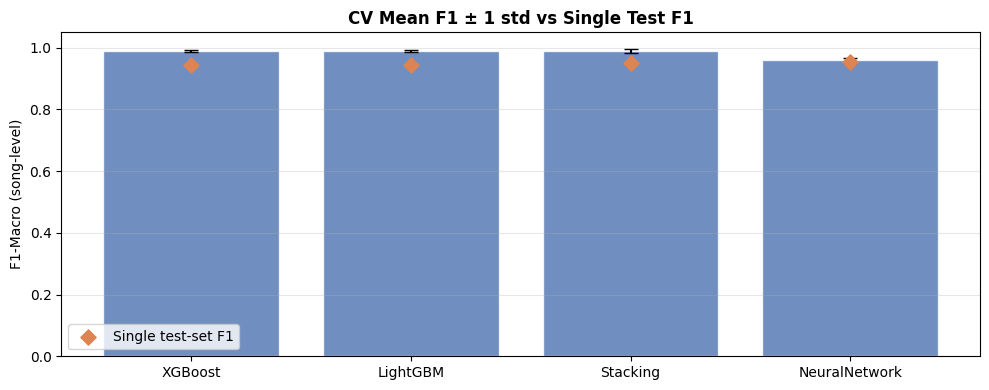


💡 A large gap between CV mean and test F1 may indicate the test split is atypically easy or hard.
   High std (> 0.05) means model performance is sensitive to which songs end up in the held-out set.


In [23]:
# ── 5-fold CV variance estimation on trainval set (song groups respected) ──
from sklearn.model_selection import StratifiedGroupKFold

CV_N_SPLITS = 5
sgkf_cv = StratifiedGroupKFold(n_splits=CV_N_SPLITS, shuffle=True, random_state=SEED)

# Re-encode trainval strat key for CV stratification
# (reuse strat_enc but sliced to trainval indices)
X_tv_scaled = scaler.transform(X_trainval)   # scale without refitting
cv_results   = {name: [] for name in trained_models if name not in ('WeightedVoting',)}

_prob_cols_cv = le.classes_.tolist()

for fold, (tr, vl) in enumerate(sgkf_cv.split(
        X_tv_scaled, y_trainval, groups=groups_trainval)):
    X_fold_val  = X_tv_scaled[vl]
    y_fold_val  = y_trainval[vl]
    g_fold_val  = groups_trainval.iloc[vl]

    for name, model in trained_models.items():
        if name == 'WeightedVoting':
            continue
        if name == 'Stacking':
            # Stacking meta-model expects song-level probs from base models concatenated
            parts = []
            for bname, bmodel in trained_models.items():
                if bname in ('Stacking', 'WeightedVoting'):
                    continue
                if bname == 'NeuralNetwork':
                    bp = bmodel.predict(X_fold_val, verbose=0)
                else:
                    bp = bmodel.predict_proba(X_fold_val)
                df_bp = pd.DataFrame(bp, columns=_prob_cols_cv)
                df_bp['song_id'] = g_fold_val.values
                agg = df_bp.groupby('song_id')[_prob_cols_cv].max() if BEST_POOLING == 'max' \
                      else df_bp.groupby('song_id')[_prob_cols_cv].mean()
                parts.append(agg.values)
            fold_stack_X   = np.hstack(parts)
            song_ids_fold  = agg.index
            y_fold_song    = pd.Series(y_fold_val, index=g_fold_val.values)\
                               .groupby(level=0).first().loc[song_ids_fold].values
            y_fold_pred    = model.predict(fold_stack_X)
            f1_fold = f1_score(y_fold_song, y_fold_pred, average='macro')
            cv_results[name].append(f1_fold)
            continue

        if name == 'NeuralNetwork':
            probs_fold = model.predict(X_fold_val, verbose=0)
        else:
            probs_fold = model.predict_proba(X_fold_val)

        df_pf = pd.DataFrame(probs_fold, columns=_prob_cols_cv)
        df_pf['song_id'] = g_fold_val.values
        df_pf['y_true']  = y_fold_val
        if BEST_POOLING == 'max':
            sp = df_pf.groupby('song_id')[_prob_cols_cv].max()
        else:
            sp = df_pf.groupby('song_id')[_prob_cols_cv].mean()
        sy = df_pf.groupby('song_id')['y_true'].first().astype(int)
        y_fp = sp.values.argmax(axis=1)
        cv_results[name].append(f1_score(sy.values, y_fp, average='macro'))

    print(f"  CV fold {fold+1}/{CV_N_SPLITS} done")

# ── Summary table ─────────────────────────────────────────────────────────────
# Map each model to its single scalar F1 score matching the chosen BEST_POOLING strategy
test_f1_map = df_results[df_results['Pooling'] == BEST_POOLING].set_index('Model')['F1-Macro'].to_dict()

cv_summary = []
for name, scores in cv_results.items():
    arr = np.array(scores)
    cv_summary.append({
        'Model'   : name,
        'CV Mean F1' : round(arr.mean(), 4),
        'CV Std F1'  : round(arr.std(),  4),
        'CV Min F1'  : round(arr.min(),  4),
        'CV Max F1'  : round(arr.max(),  4),
        'Test F1'    : test_f1_map.get(name, '—'),  # Safely retrieves a single scalar float or '—'
    })

df_cv = pd.DataFrame(cv_summary).sort_values('CV Mean F1', ascending=False).reset_index(drop=True)
print("\n5-Fold CV Variance Estimation (song-level F1-macro):")
display(df_cv)

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(df_cv))
bars = ax.bar(x, df_cv['CV Mean F1'], yerr=df_cv['CV Std F1'],
              capsize=5, color='#4C72B0', alpha=0.8, edgecolor='white', error_kw={'lw': 1.5})
ax.scatter(x, df_cv['Test F1'].replace('—', np.nan).astype(float),
           color='#DD8452', zorder=5, s=60, label='Single test-set F1', marker='D')
ax.set_xticks(x)
ax.set_xticklabels(df_cv['Model'])
ax.set_ylabel('F1-Macro (song-level)')
ax.set_title('CV Mean F1 ± 1 std vs Single Test F1', fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 A large gap between CV mean and test F1 may indicate the test split is atypically easy or hard.")
print("   High std (> 0.05) means model performance is sensitive to which songs end up in the held-out set.")


## 10 · Save Trained Models

Export all trained models and preprocessing objects so they can be published
as a Kaggle Dataset and reused for inference without retraining.

| Artifact | File | Purpose |
|---|---|---|
| StandardScaler | `scaler.joblib` | Reproduces the exact feature scaling used during training |
| LabelEncoder | `label_encoder.joblib` | Maps predicted class indices back to genre names |
| LightGBM | `lightgbm_model.joblib` | Best LightGBM classifier after Optuna tuning |
| XGBoost | `xgboost_model.joblib` | Best XGBoost classifier after Optuna tuning |
| Neural Network | `neural_network.keras` | Best Keras model retrained for 50 epochs |

> ⚠️ The **scaler** and **label encoder** are required for any inference — always
> load them alongside the model files.

In [24]:
import joblib, os
from datetime import datetime

# Include a timestamp so re-runs don't silently overwrite previous artefacts
run_id   = datetime.now().strftime('%Y%m%d_%H%M%S')
save_dir = f"/kaggle/working/models/{run_id}"
os.makedirs(save_dir, exist_ok=True)

# Scaler & label encoder (needed for inference)
joblib.dump(scaler, f"{save_dir}/scaler.joblib")
joblib.dump(le,     f"{save_dir}/label_encoder.joblib")

# Tree models (save calibrated wrappers AND raw base estimators)
joblib.dump(best_lgb_cal, f"{save_dir}/lightgbm_model.joblib")
joblib.dump(best_xgb_cal, f"{save_dir}/xgboost_model.joblib")

# Neural network (Keras native format)
best_nn.save(f"{save_dir}/neural_network.keras")

# Ensemble meta-models
joblib.dump(meta_model, f"{save_dir}/stacking_meta.joblib")
np.save(f"{save_dir}/weighted_voting_weights.npy", best_w)
# Save model name order so weights can be matched correctly at inference
joblib.dump(model_names_base, f"{save_dir}/weighted_voting_model_order.joblib")

# Write a small manifest for traceability
manifest = {
    'run_id'       : run_id,
    'SEED'         : SEED,
    'best_pooling' : BEST_POOLING,
    'model_order'  : model_names_base,
    'weighted_voting_weights': {n: round(w, 4) for n, w in zip(model_names_base, best_w)},
}
import json
with open(f"{save_dir}/manifest.json", 'w') as fh:
    json.dump(manifest, fh, indent=2)

print(f"All models saved to {save_dir}")
print(f"Weighted voting weights: { {n: round(w,3) for n,w in zip(model_names_base, best_w)} }")


All models saved to /kaggle/working/models/20260521_140358
Weighted voting weights: {'LightGBM': np.float64(0.353), 'XGBoost': np.float64(0.146), 'NeuralNetwork': np.float64(0.5)}
